# Drought Forecast Verification — Template Notebook

This notebook demonstrates the full `drought-forecast-eval` workflow:

1. **Download** (optional) fresh data from BGDI
2. **Load** forecast archive and observation archive
3. **Align** observations to the forecast grid
4. **Build** a reference forecast (climatology or persistence)
5. **Compute** verification scores
6. **Visualise** skill curves and regional maps
7. **Export** results (NetCDF, CSV, HTML report)

Copy this notebook and adapt the paths / settings for your specific experiment.

---
**Docs:** `docs/` | **Source:** `drought_forecast_eval/` | **Issues / MRs:** GitLab repo

In [1]:
%load_ext autoreload
%autoreload 2

In [80]:
from pathlib import Path

# ── EDIT THESE PATHS ──────────────────────────────────────────────────────
DATA_DIR     = Path("data")                          # root data dir

ARCHIVE_DIR   = DATA_DIR / "zipfiles"               # flat dir of daily ZIPs
HISTORIC_ZIP  = DATA_DIR / "historic.csv.zip"      # full observation archive
NC_DIR = DATA_DIR / "netcdf"                            # netCDF dir
SHAPEFILE     = Path('shapefiles/BAFU_Grossregionen_v3.shp')
OUTPUT_DIR    = Path("output")

DATE_RANGE    = ("2025-04-01", "2026-08-20")        # verification window
REGIONS       = "all"                                # or e.g. [1, 5, 12, 31]
VARIABLES     = "all"                                # or e.g. ["spi_1m", "cdi"]
CDI_THRESHOLD = 2                                    # CDI ≥ threshold = drought event
# ──────────────────────────────────────────────────────────────────────────

In [3]:
! mkdir -p {NC_DIR}

## 1. (Optional) Download fresh data from BGDI

In [4]:
from drought_forecast_eval.io.downloader import download_archive, download_historic

# Uncomment to download:
# download_archive(ARCHIVE_DIR, start=DATE_RANGE[0], end=DATE_RANGE[1])
download_historic(HISTORIC_ZIP)


PosixPath('data/historic.csv.zip')

## 2. Load data

In [92]:
from drought_forecast_eval.io.loader import load_forecasts, load_observations_combined
import xarray as xr

RECREATE_NETCDF = True  # set to True to re-create netCDF files from raw data

date_today = "2026-08-21"

if RECREATE_NETCDF:
    ds_fcst = load_forecasts(ARCHIVE_DIR, date_range=DATE_RANGE)
    ds_obs  = load_observations_combined(HISTORIC_ZIP, archive_dir=ARCHIVE_DIR)
    ds_fcst.to_netcdf(NC_DIR / f"forecasts_{date_today}.nc")
    ds_obs.to_netcdf(NC_DIR / f"observations_{date_today}.nc")
else:
    ds_fcst = xr.open_dataset(NC_DIR / f"forecasts_{date_today}.nc")
    ds_obs  = xr.open_dataset(NC_DIR / f"observations_{date_today}.nc")


trockenheitsdaten-numerisch_current.csv.202509192100.zip: filename date (2025-09-19) differs from header date (2025-09-18); using filename date.
trockenheitsdaten-numerisch_current.csv.202511042100.zip: filename date (2025-11-04) differs from header date (2025-11-03); using filename date.
trockenheitsdaten-numerisch_current.csv.202601082100.zip: filename date (2026-01-08) differs from header date (2026-01-07); using filename date.
trockenheitsdaten-numerisch_current.csv.202606212100.zip: filename date (2026-06-21) differs from header date (2026-06-20); using filename date.


In [93]:
ds_fcst

<xarray.Dataset> Size: 20MB
Dimensions:                  (forecast_reference_time: 410,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 3kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 499kB ...
Data variables: (12/39)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    ...                       ...
    spi_24m_p10              (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    spi_24m_p50              (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    spi_24m_p90              (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    soil_moisture_ufc_p10    (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    soil_moisture_ufc_p50    (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    soil_moisture_ufc_p90    (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

In [108]:
ds_obs

<xarray.Dataset> Size: 10MB
Dimensions:              (drought_region_id: 38, valid_at: 1860)
Coordinates:
  * drought_region_id    (drought_region_id) int64 304B 31 32 33 34 ... 66 67 68
  * valid_at             (valid_at) datetime64[ns] 15kB 1990-12-31 ... 2026-0...
Data variables: (12/18)
    cdi                  (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_1m_index      (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_3m_index      (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_24m_index     (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    hydro_index          (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    soil_moisture_index  (drought_region_id, valid_at) float64 565kB nan ... nan
    ...                   ...
    spi_3m               (drought_region_id, valid_at) float64 565kB 0.77 ......
    spi_6m               (drought_region_id, valid_at) float64 565kB 0.4 ... nan
    spi_12m              (drought_region_id, valid_at) float64 565kB 0.82 ......
    spi_24m              (drought_region_id, valid_at) float64 565kB -0.47 .....
    soil_moisture_ufc    (drought_region_id, valid_at) float64 565kB nan ... ...
    vhi                  (drought_region_id, valid_at) float64 565kB nan ... nan
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought observation archive (historic + current)

## 3. Align observations to the forecast grid

In [95]:
from drought_forecast_eval import align_obs_to_forecast

if RECREATE_NETCDF:
    ds_merged = align_obs_to_forecast(ds_fcst, ds_obs)
    print("Merged dataset dims:", dict(ds_merged.dims))
    ds_merged.to_netcdf(NC_DIR / "merged.nc")
else:
    ds_merged = xr.open_dataset(NC_DIR / "merged.nc")

Merged dataset dims: {'forecast_reference_time': 410, 'drought_region_id': 38, 'lead_week': 4}


/tmp/ipykernel_4694/2878378011.py:5: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print("Merged dataset dims:", dict(ds_merged.dims))


In [96]:
ds_merged

<xarray.Dataset> Size: 29MB
Dimensions:                  (forecast_reference_time: 410,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 3kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 499kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

In [97]:
mask = ds_merged["forecast_reference_time"].dt.weekday == 0
ds_mondays = ds_merged.isel(forecast_reference_time=mask.values)

In [98]:
ds_mondays

<xarray.Dataset> Size: 4MB
Dimensions:                  (forecast_reference_time: 57,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 456B 20...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 69kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

In [109]:
ds_mondays.spi_1m_obs

<xarray.DataArray 'spi_1m_obs' (forecast_reference_time: 57,
                                drought_region_id: 38, lead_week: 4)> Size: 69kB
array([[[-1.12, -0.81,  0.57,  1.11],
        [-1.14, -0.66,  0.66,  1.06],
        [-1.63, -0.73,  0.59,  1.06],
        ...,
        [-0.1 ,  0.04,  0.63,  0.64],
        [ 0.  ,  0.26,  0.95,  0.82],
        [ 0.62,  0.7 ,  1.37,  1.18]],

       [[-0.81,  0.57,  1.11,  0.57],
        [-0.66,  0.66,  1.06,  0.46],
        [-0.73,  0.59,  1.06,  0.61],
        ...,
        [ 0.04,  0.63,  0.64, -0.1 ],
        [ 0.26,  0.95,  0.82,  0.05],
        [ 0.7 ,  1.37,  1.18,  0.26]],

       [[ 0.57,  1.11,  0.57,  0.18],
        [ 0.66,  1.06,  0.46, -0.02],
        [ 0.59,  1.06,  0.61,  0.06],
        ...,
...
        ...,
        [-1.05, -0.99,   nan,   nan],
        [-1.53, -1.46,   nan,   nan],
        [-0.86, -0.99,   nan,   nan]],

       [[-3.52,   nan,   nan,   nan],
        [-2.98,   nan,   nan,   nan],
        [-3.18,   nan,   nan,   nan],
        ...,
        [-0.99,   nan,   nan,   nan],
        [-1.46,   nan,   nan,   nan],
        [-0.99,   nan,   nan,   nan]],

       [[  nan,   nan,   nan,   nan],
        [  nan,   nan,   nan,   nan],
        [  nan,   nan,   nan,   nan],
        ...,
        [  nan,   nan,   nan,   nan],
        [  nan,   nan,   nan,   nan],
        [  nan,   nan,   nan,   nan]]], shape=(57, 38, 4))
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 456B 20...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 69kB ...

## 4. Build reference forecast

Choose `"climatology"`, `"persistence"`, or `"both

In [135]:
from drought_forecast_eval import climatology_reference, persistence_reference

CLIM_PERIOD = ("1991-01-01", "2020-12-31")  # WMO standard climate normal

if RECREATE_NETCDF:
    ds_ref_clim = climatology_reference(ds_obs, ds_fcst, week_window=1, valid_period=CLIM_PERIOD)
    ds_ref_pers = persistence_reference(ds_obs, ds_fcst)
    ds_ref_clim.to_netcdf(NC_DIR / "climatology_reference.nc")
    ds_ref_pers.to_netcdf(NC_DIR / "persistence_reference.nc")
else:
    ds_ref_clim = xr.open_dataset(NC_DIR / "climatology_reference.nc")
    ds_ref_pers = xr.open_dataset(NC_DIR / "persistence_reference.nc")


print("Climatology reference variables:", list(ds_ref_clim.data_vars)[:5], "...")

/home/ima/.cache/pypoetry/virtualenvs/drought-forecast-eval-Gg7LaOIY-py3.12/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Climatology reference variables: ['cdi_ref_p10', 'cdi_ref_p50', 'cdi_ref_p90', 'precip_1m_index_ref_p10', 'precip_1m_index_ref_p50'] ...


## 5 Explorative Data Analysis

In [14]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


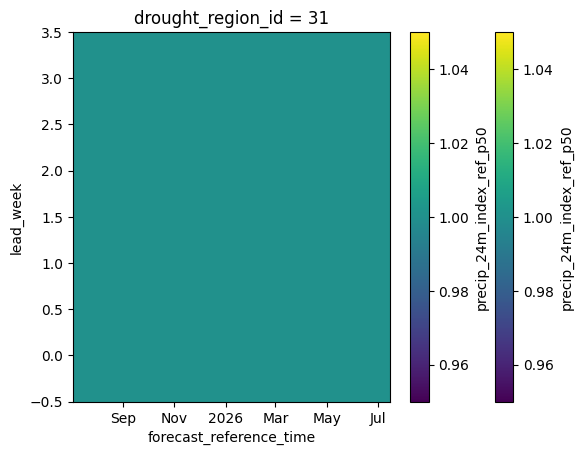

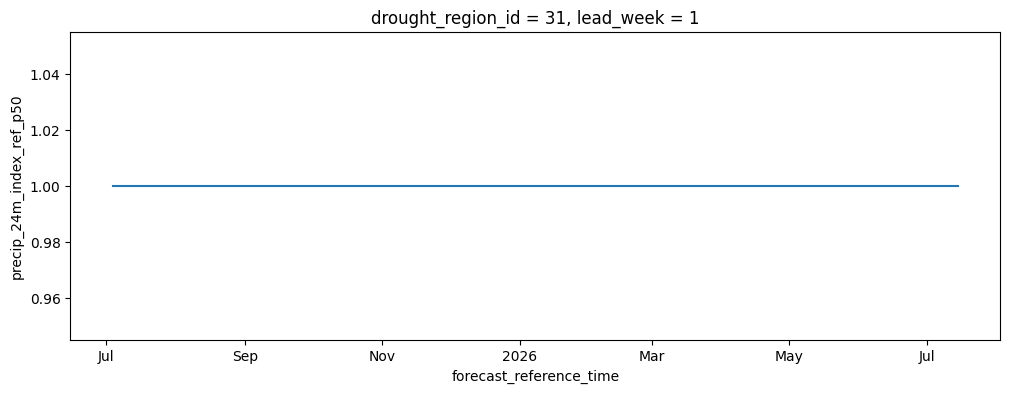

In [22]:
import matplotlib.pylab as plt

%matplotlib inline
plt.show()

In [139]:
RID = 42 # Region Identifier
VALIDATION_RANGE = slice("2026-01-01", "2026-08-20")

In [52]:
from drought_forecast_eval.visualization.skill_curves import plot_forecast_plume

In [119]:
ds_ref_pers

<xarray.Dataset> Size: 9MB
Dimensions:                      (forecast_reference_time: 410,
                                  drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time      (forecast_reference_time) datetime64[us] 3kB ...
  * drought_region_id            (drought_region_id) int64 304B 31 32 ... 67 68
  * lead_week                    (lead_week) int64 32B 0 1 2 3
Data variables: (12/18)
    cdi_ref_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_1m_index_ref_p50      (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_3m_index_ref_p50      (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    precip_24m_index_ref_p50     (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    hydro_index_ref_p50          (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    soil_moisture_index_ref_p50  (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    ...                           ...
    spi_3m_ref_p50               (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    spi_6m_ref_p50               (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    spi_12m_ref_p50              (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    spi_24m_ref_p50              (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    soil_moisture_ufc_ref_p50    (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
    vhi_ref_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 499kB ...
Attributes:
    reference_type:  persistence

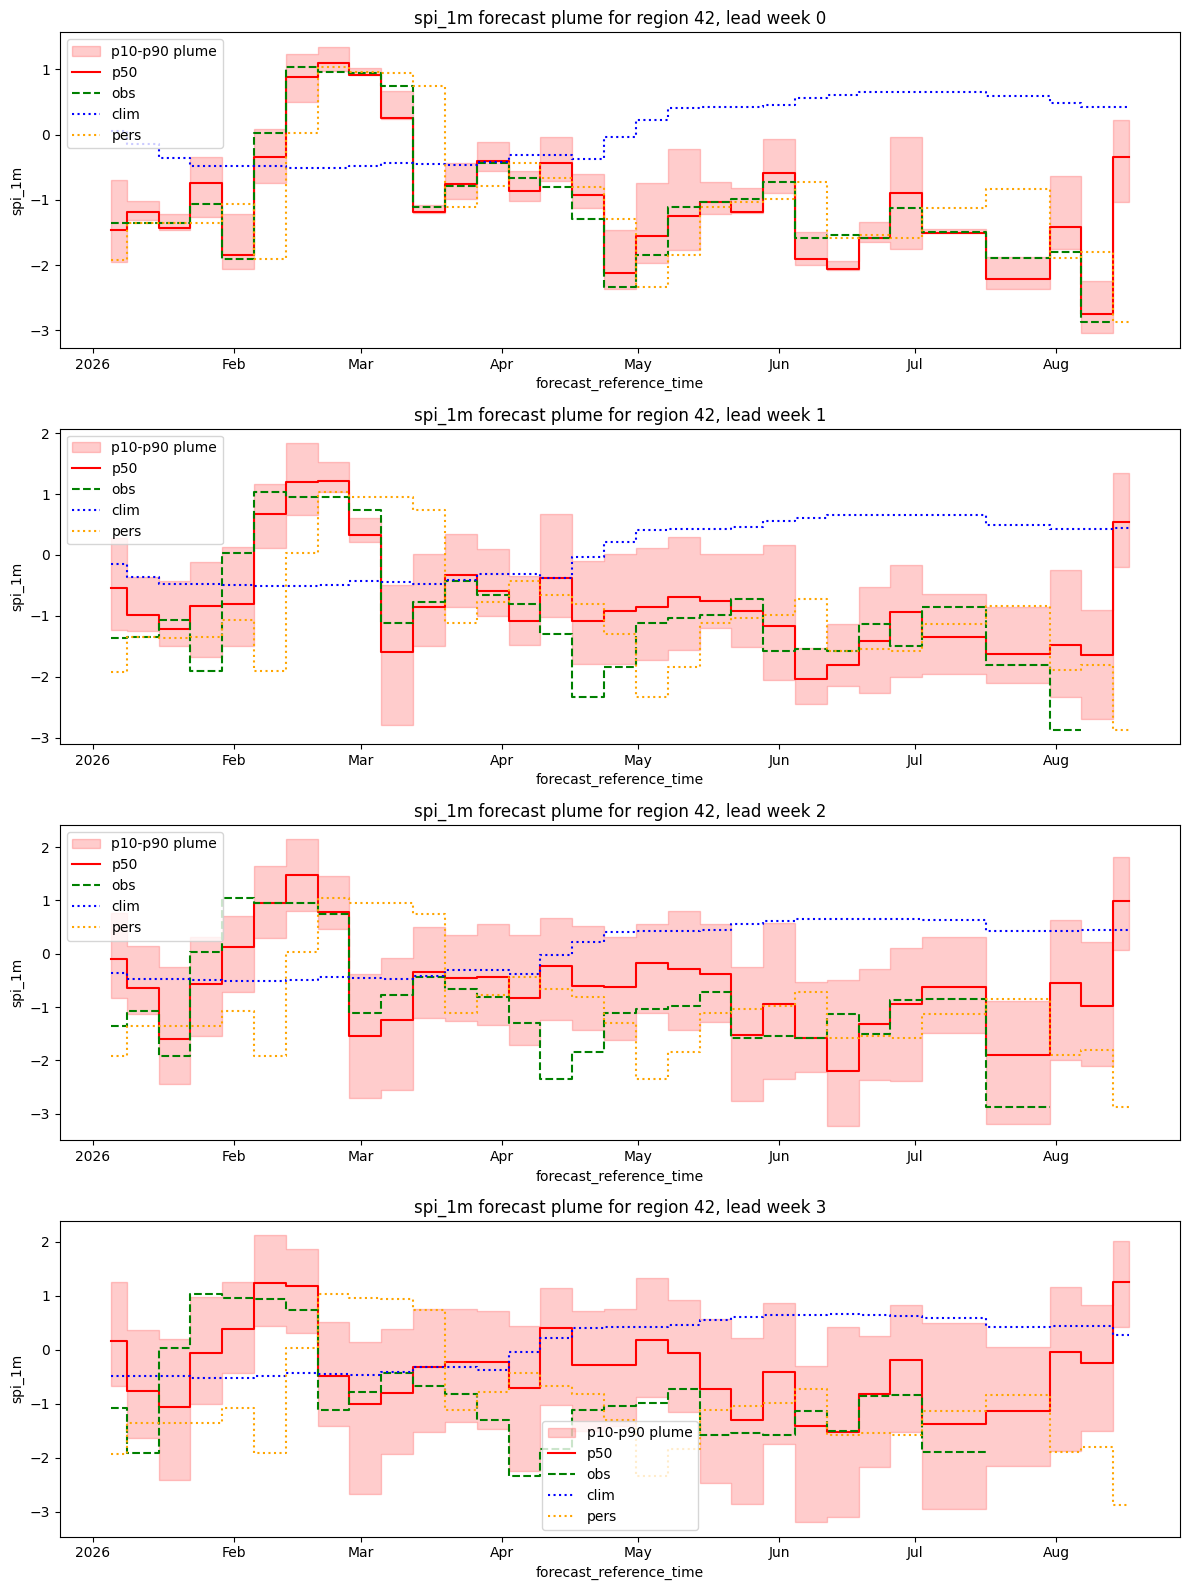

In [140]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays.sel(forecast_reference_time=VALIDATION_RANGE),
                    ds_ref_clim=ds_ref_clim,
                    ds_ref_pers=ds_ref_pers,
                    rid=RID,
                    var="spi_1m",
                    time_dim="forecast_reference_time")

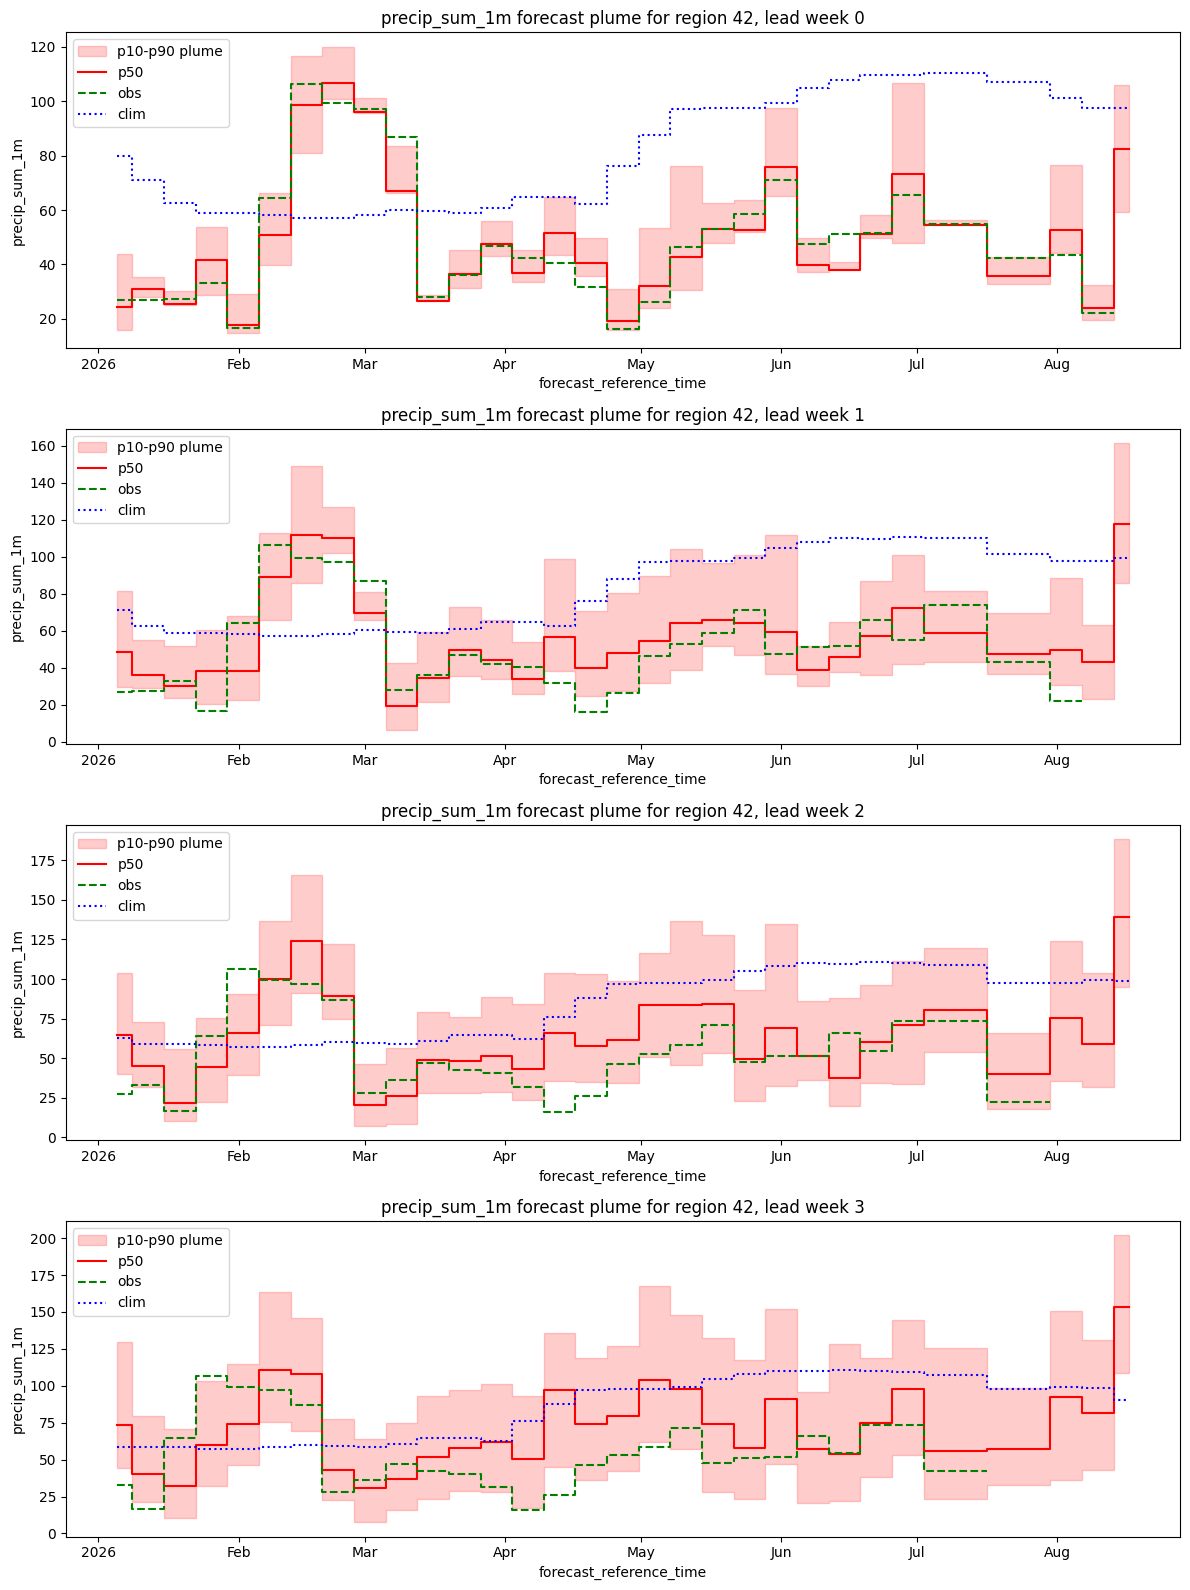

In [ ]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays.sel(forecast_reference_time=VALIDATION_RANGE),
                    ds_ref_clim=ds_ref_clim,
                    #ds_ref_pers=ds_ref_pers,
                    rid=RID,
                    var="precip_sum_1m")


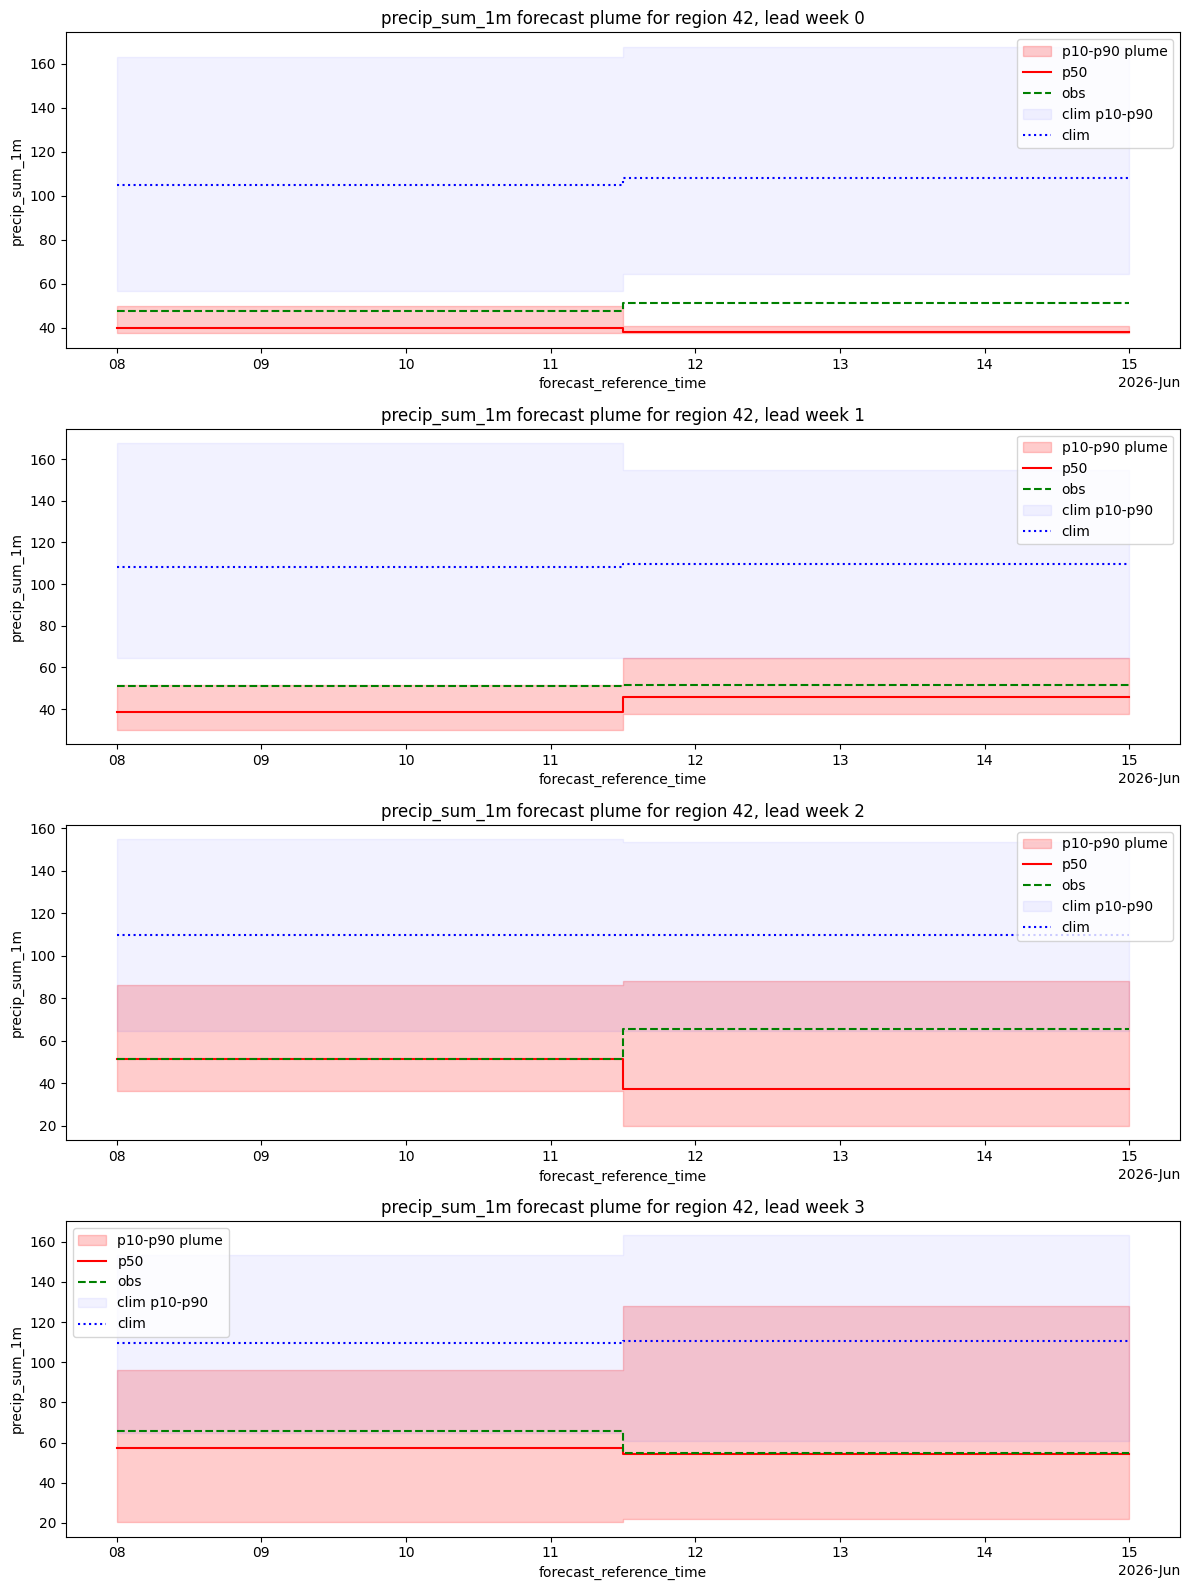

In [216]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays.sel(forecast_reference_time=slice("2026-06-08", "2026-06-15")),
                    ds_ref_clim=ds_ref_clim,
                    #ds_ref_pers=ds_ref_pers,
                    rid=42,
                    var="precip_sum_1m",
                    clim_dressed=True)


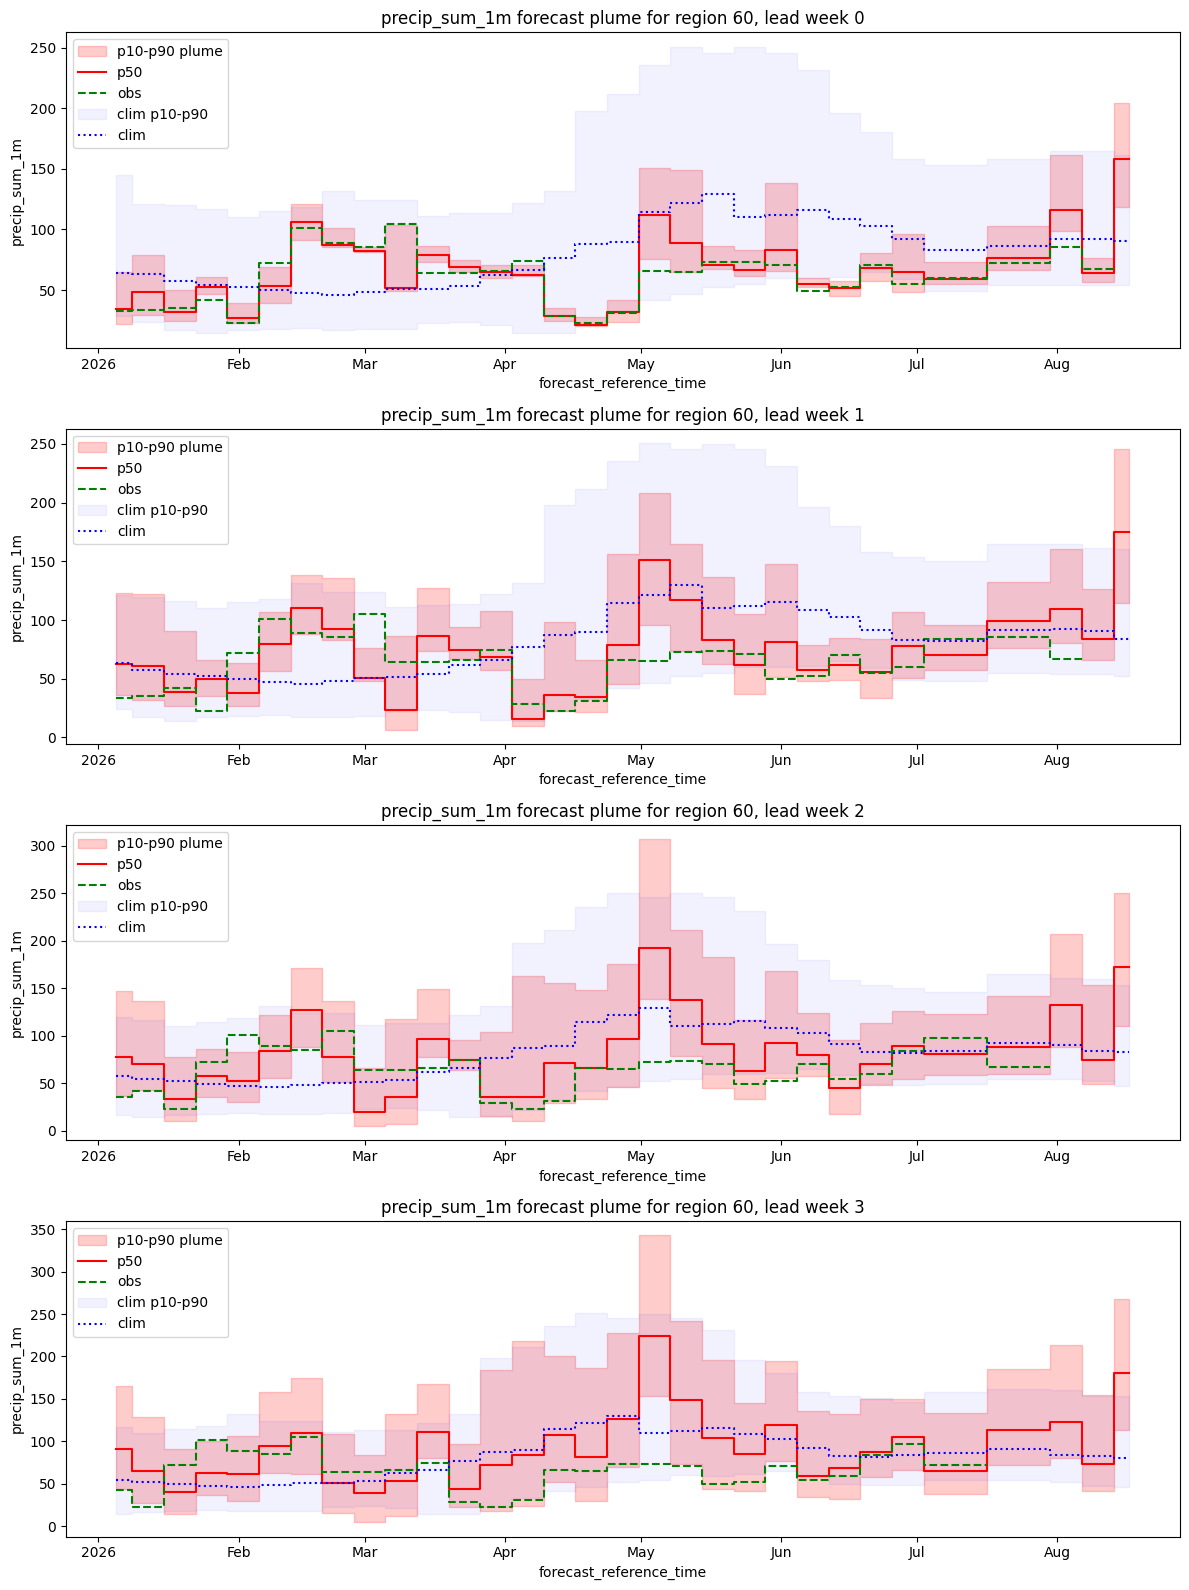

In [160]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays.sel(forecast_reference_time=slice("2026-01-01", "2026-08-20")),
                    ds_ref_clim=ds_ref_clim,
                    #ds_ref_pers=ds_ref_pers,
                    rid=60,
                    var="precip_sum_1m",
                    clim_dressed=True)


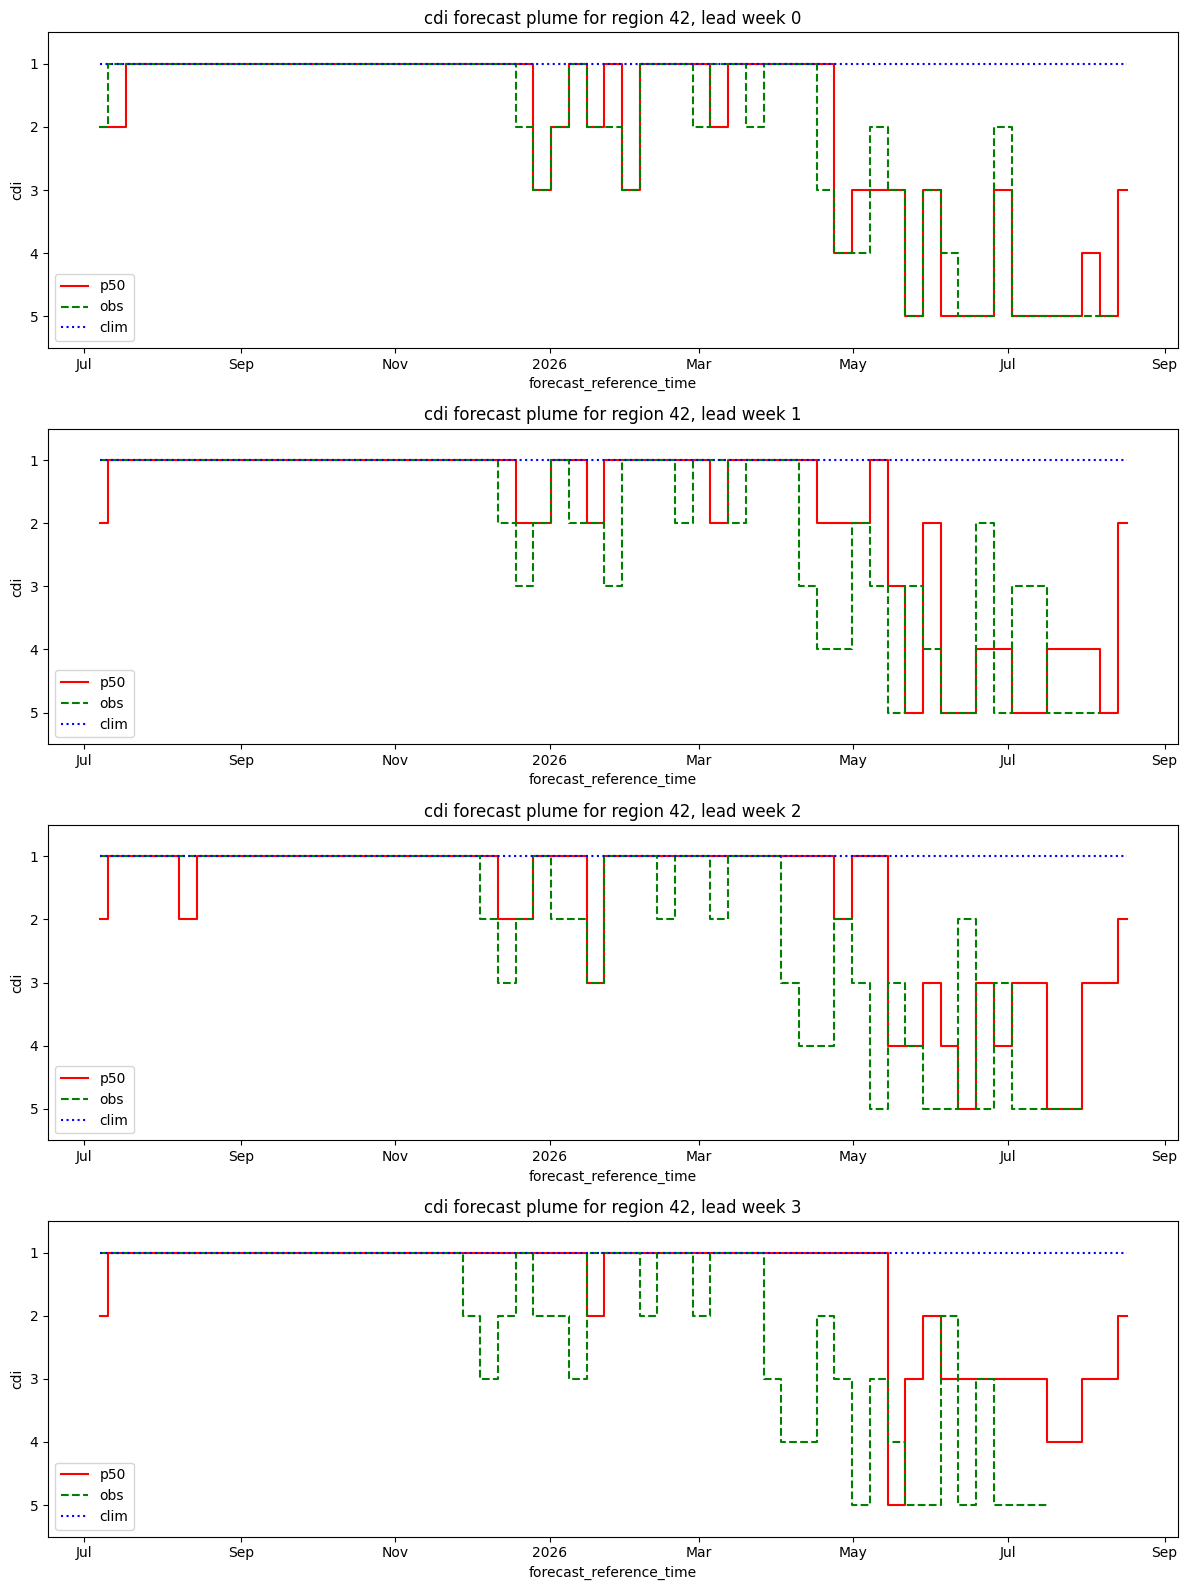

In [158]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays,
                    ds_ref_clim=ds_ref_clim,
                    #ds_ref_pers=ds_ref_pers,
                    rid=42,
                    var="cdi")

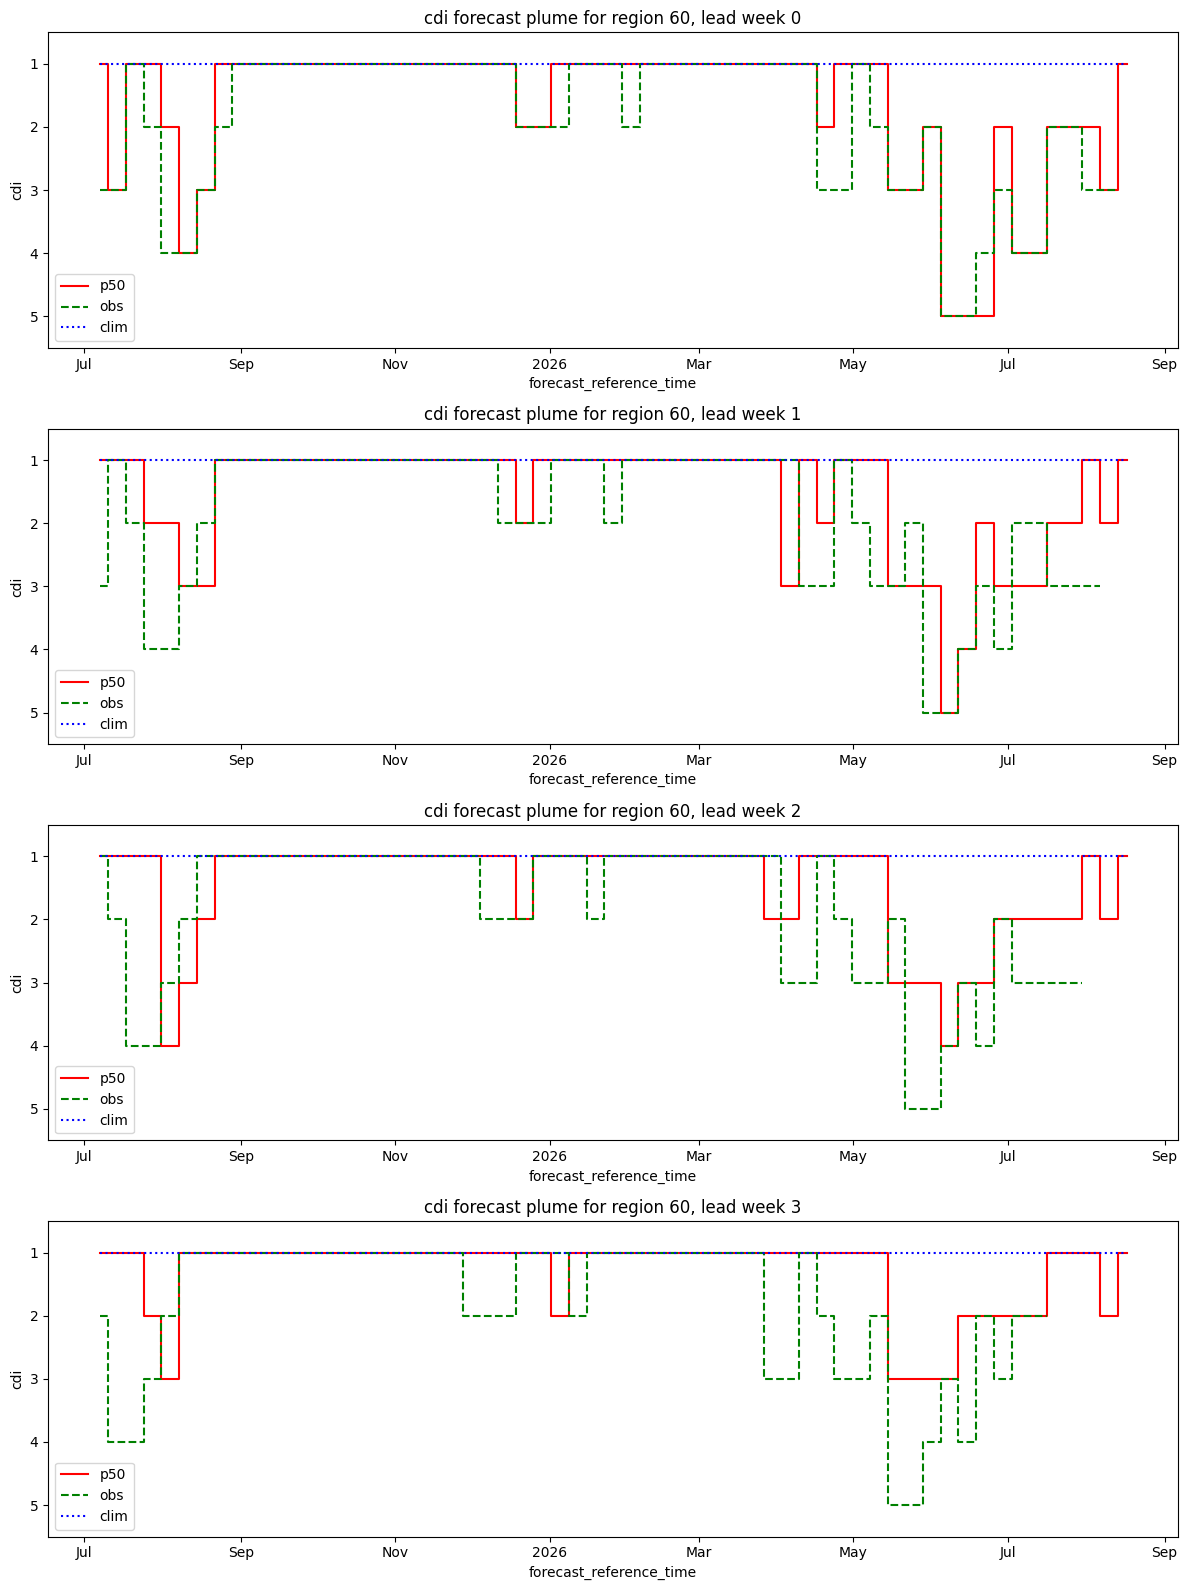

In [161]:
fig, ax = plot_forecast_plume(ds_merged=ds_mondays,
                    ds_ref_clim=ds_ref_clim,
                    #ds_ref_pers=ds_ref_pers,
                    rid=60,
                    var="cdi")

## 6. Compute scores

In [162]:
from drought_forecast_eval import compute_scores
import numpy as np

frt = ds_mondays["forecast_reference_time"]
mask = (
    ((frt >= np.datetime64("2026-03-01")) & (frt <= np.datetime64("2026-09-01")))
)
ds_sel = ds_mondays.isel(forecast_reference_time=mask.values)

ds_scores = compute_scores(
    ds_sel,
    variables=VARIABLES,
    scores="default",
    ds_ref=ds_ref_clim,
    cdi_threshold=CDI_THRESHOLD,
)

print("Score variables:", list(ds_scores.data_vars))

Score variables: ['cdi_mae', 'cdi_rmse', 'cdi_bias', 'cdi_correlation', 'precip_1m_index_mae', 'precip_1m_index_rmse', 'precip_1m_index_bias', 'precip_1m_index_correlation', 'precip_3m_index_mae', 'precip_3m_index_rmse', 'precip_3m_index_bias', 'precip_3m_index_correlation', 'precip_24m_index_mae', 'precip_24m_index_rmse', 'precip_24m_index_bias', 'precip_24m_index_correlation', 'hydro_index_mae', 'hydro_index_rmse', 'hydro_index_bias', 'hydro_index_correlation', 'soil_moisture_index_mae', 'soil_moisture_index_rmse', 'soil_moisture_index_bias', 'soil_moisture_index_correlation', 'precip_sum_1m_mae', 'precip_sum_1m_rmse', 'precip_sum_1m_bias', 'precip_sum_1m_correlation', 'precip_sum_1m_pinball', 'precip_sum_1m_interval_score', 'precip_sum_3m_mae', 'precip_sum_3m_rmse', 'precip_sum_3m_bias', 'precip_sum_3m_correlation', 'precip_sum_3m_pinball', 'precip_sum_3m_interval_score', 'precip_sum_6m_mae', 'precip_sum_6m_rmse', 'precip_sum_6m_bias', 'precip_sum_6m_correlation', 'precip_sum_6m_pin

In [163]:
ds_scores

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

### 5a. Add custom metrics
You can register your own scoring function and include it by name:

In [165]:
import xarray as xr
from drought_forecast_eval import register_score

def my_custom_score(fcst: xr.DataArray, obs: xr.DataArray, **kwargs) -> xr.DataArray:
    """Example: mean signed error."""
    return (fcst - obs).mean(dim=kwargs.get("reduce_dims", []))

register_score("signed_error", my_custom_score)

ds_scores_custom = compute_scores(
    ds_merged,
    variables=["spi_1m", "cdi"],
    scores=["mae", "signed_error"],
)
ds_scores_custom

<xarray.Dataset> Size: 3kB
Dimensions:            (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id  (drought_region_id) int64 304B 31 32 33 34 ... 66 67 68
  * lead_week          (lead_week) int64 32B 0 1 2 3
Data variables:
    spi_1m_mae         (drought_region_id, lead_week) float64 1kB 0.1298 ... ...
    cdi_mae            (drought_region_id, lead_week) float64 1kB 0.1355 ... ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  spi_1m,cdi
    scores_computed:   mae,signed_error
    cdi_threshold:     2.0
    reference_type:    none

## 6. Visualise results

In [166]:
ds_scores

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

In [167]:
import matplotlib.pyplot as plt
from drought_forecast_eval.visualization import plot_skill_vs_lead
from drought_forecast_eval.visualization.region_map import plot_region_polygon

(<Figure size 1200x1000 with 1 Axes>, <Axes: >)

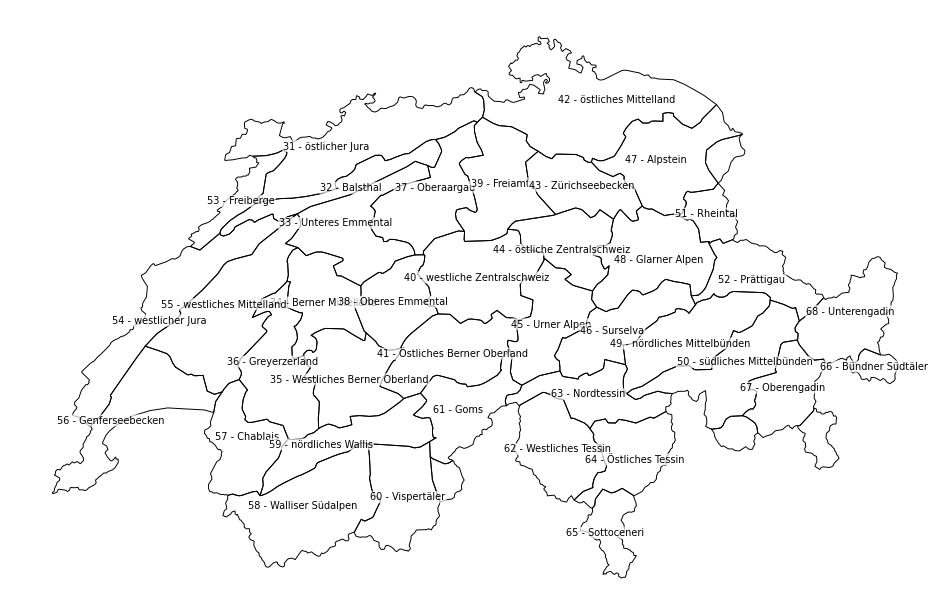

In [168]:
plot_region_polygon()

In [169]:
RID_PLATEAU = [55,33,37,32,39,43,42]

RID_ALPS = [57,59,58,60,61,63,45,46,49,50,67]

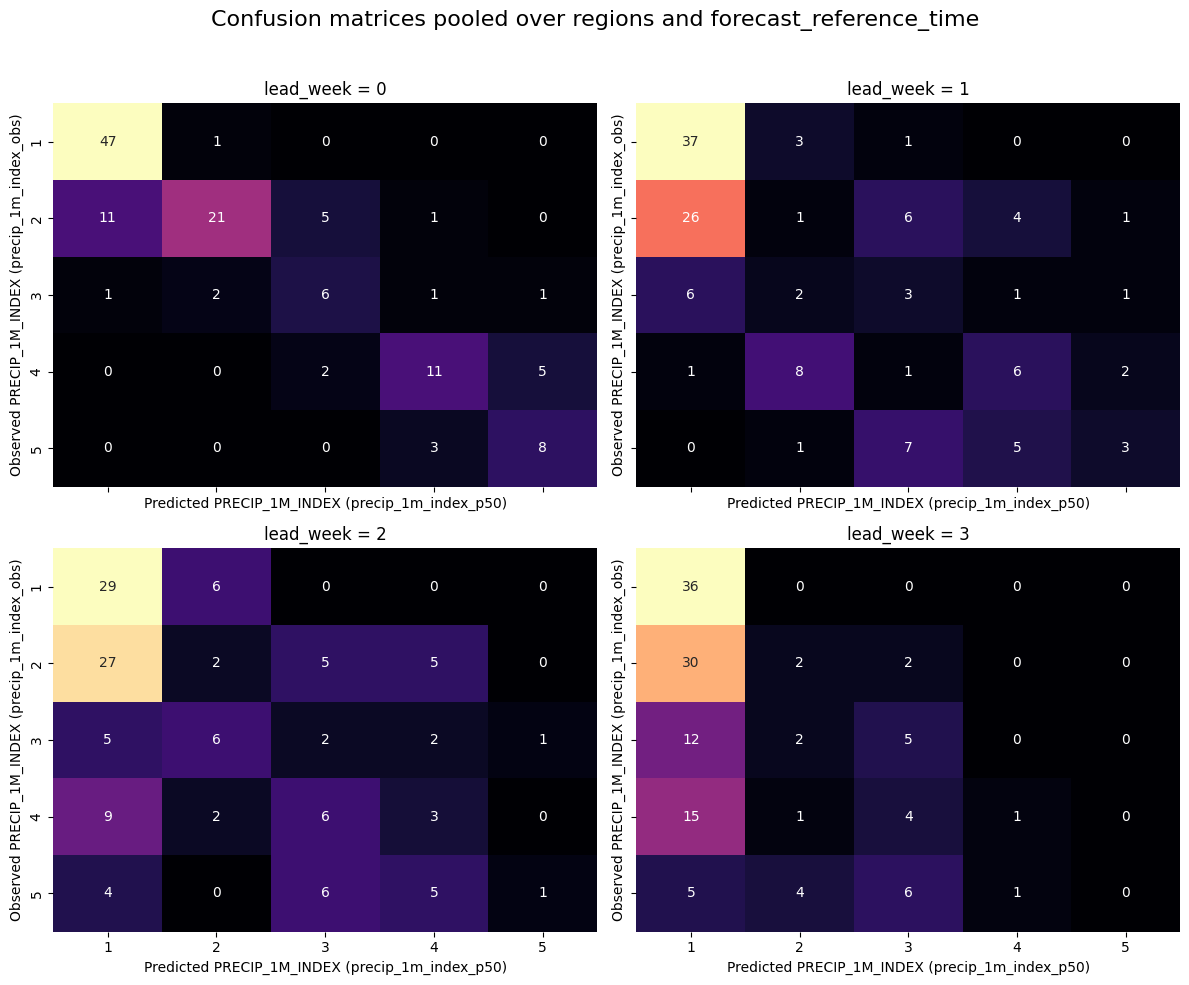

In [231]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ds is your xarray dataset
# set `var` to choose variable (base name), e.g. "cdi", "precip_sum_1m", "soil_moisture_ufc"
var = "precip_1m_index"
obs = f"{var}_obs"
p50 = f"{var}_p50"
df = ds_mondays[[obs, p50]].sel(forecast_reference_time=slice("2026-03-01","2026-07-01")).sel(drought_region_id=RID_PLATEAU).to_dataframe().reset_index()

# if your CDI classes are 1..5
levels = np.arange(1, 6)

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

for ax, lead in zip(axes.ravel(), sorted(df["lead_week"].unique())):
    subset = df[df["lead_week"] == lead]
    y_true = subset[obs].astype(int)
    y_pred = subset[p50].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=levels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="magma",
        xticklabels=levels,
        yticklabels=levels,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"lead_week = {lead}")
    ax.set_xlabel(f"Predicted {var.upper()} ({p50})")
    ax.set_ylabel(f"Observed {var.upper()} ({obs})")

fig.suptitle("Confusion matrices pooled over regions and forecast_reference_time", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

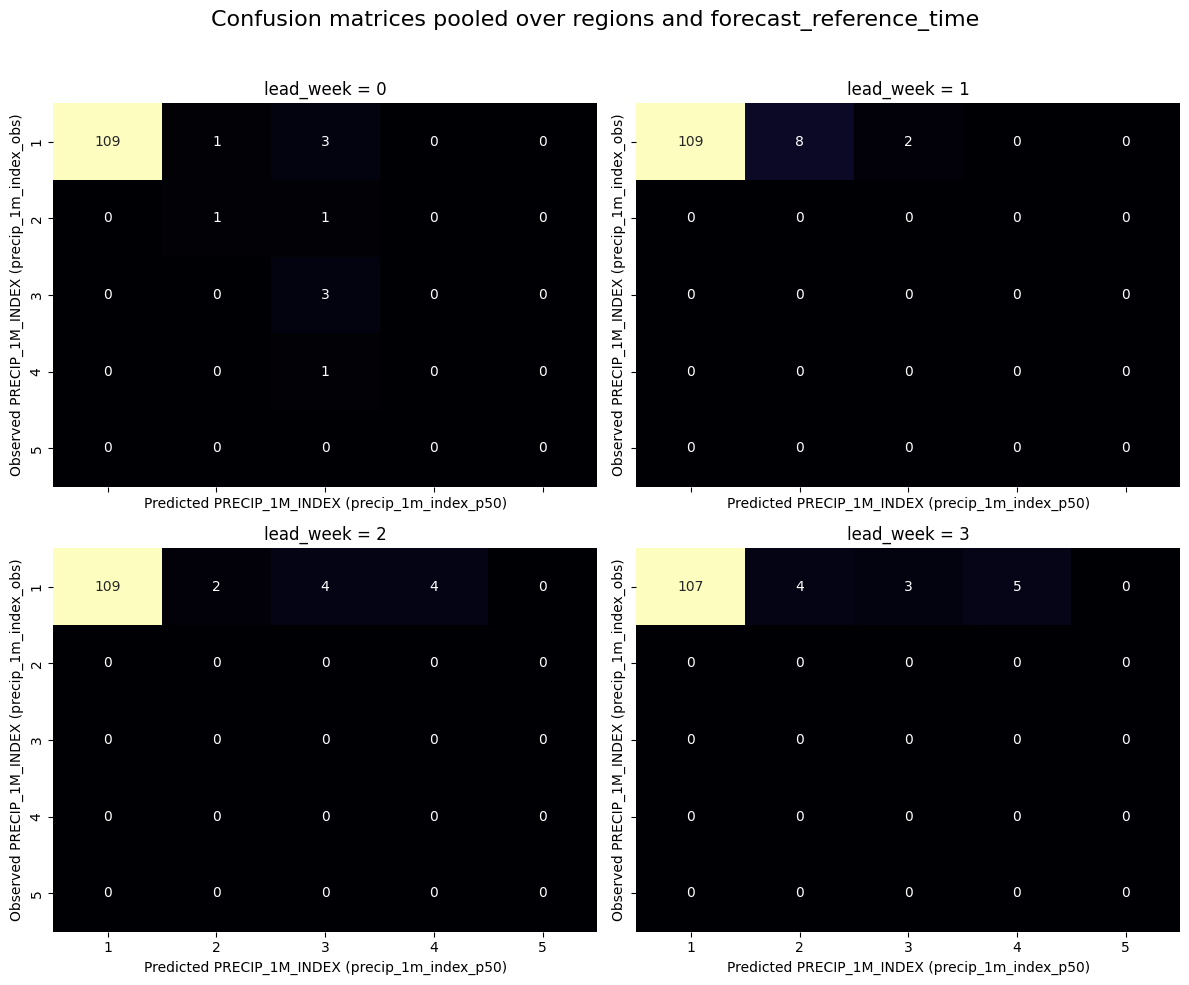

In [223]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ds is your xarray dataset
# set `var` to choose variable (base name), e.g. "cdi", "precip_sum_1m", "soil_moisture_ufc"
var = "precip_1m_index"
obs = f"{var}_obs"
p50 = f"{var}_p50"
df = ds_mondays[[obs, p50]].sel(forecast_reference_time=slice("2025-07-01","2025-10-31")).sel(drought_region_id=RID_PLATEAU).to_dataframe().reset_index()

# if your CDI classes are 1..5
levels = np.arange(1, 6)

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

for ax, lead in zip(axes.ravel(), sorted(df["lead_week"].unique())):
    subset = df[df["lead_week"] == lead]
    y_true = subset[obs].astype(int)
    y_pred = subset[p50].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=levels)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="magma",
        xticklabels=levels,
        yticklabels=levels,
        cbar=False,
        ax=ax,
    )
    ax.set_title(f"lead_week = {lead}")
    ax.set_xlabel(f"Predicted {var.upper()} ({p50})")
    ax.set_ylabel(f"Observed {var.upper()} ({obs})")

fig.suptitle("Confusion matrices pooled over regions and forecast_reference_time", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [180]:
ds_obs

<xarray.Dataset> Size: 10MB
Dimensions:              (drought_region_id: 38, valid_at: 1860)
Coordinates:
  * drought_region_id    (drought_region_id) int64 304B 31 32 33 34 ... 66 67 68
  * valid_at             (valid_at) datetime64[ns] 15kB 1990-12-31 ... 2026-0...
Data variables: (12/18)
    cdi                  (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_1m_index      (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_3m_index      (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    precip_24m_index     (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    hydro_index          (drought_region_id, valid_at) float64 565kB 1.0 ... nan
    soil_moisture_index  (drought_region_id, valid_at) float64 565kB nan ... nan
    ...                   ...
    spi_3m               (drought_region_id, valid_at) float64 565kB 0.77 ......
    spi_6m               (drought_region_id, valid_at) float64 565kB 0.4 ... nan
    spi_12m              (drought_region_id, valid_at) float64 565kB 0.82 ......
    spi_24m              (drought_region_id, valid_at) float64 565kB -0.47 .....
    soil_moisture_ufc    (drought_region_id, valid_at) float64 565kB nan ... ...
    vhi                  (drought_region_id, valid_at) float64 565kB nan ... nan
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought observation archive (historic + current)

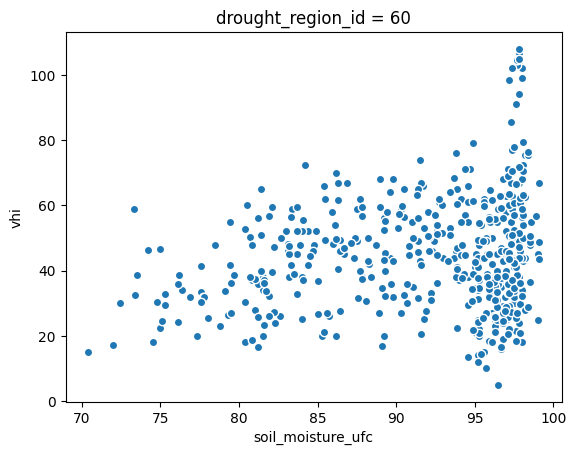

In [193]:
ds_obs.sel(drought_region_id=60).plot.scatter(x="soil_moisture_ufc", y="vhi", levels=range(5),cmap="plasma")

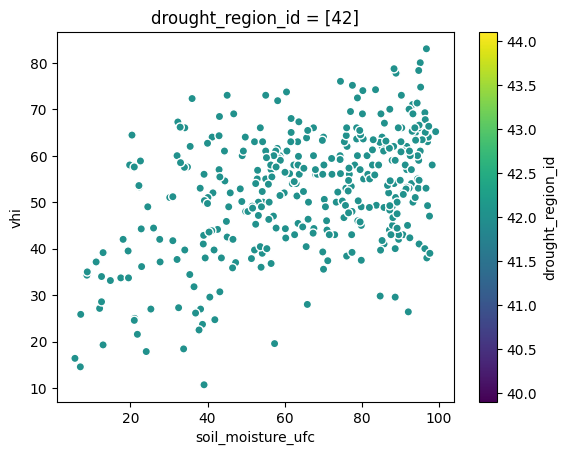

In [207]:
mask_amj = ds_obs["valid_at"].dt.month.isin([4, 5, 6, 7, 8, 9])
ds_obs.isel(valid_at=mask_amj).sel(drought_region_id=[42]).plot.scatter(x="soil_moisture_ufc", y="vhi", hue="drought_region_id")

In [218]:
ds_mondays

<xarray.Dataset> Size: 4MB
Dimensions:                  (forecast_reference_time: 57,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[us] 456B 20...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 69kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 69kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

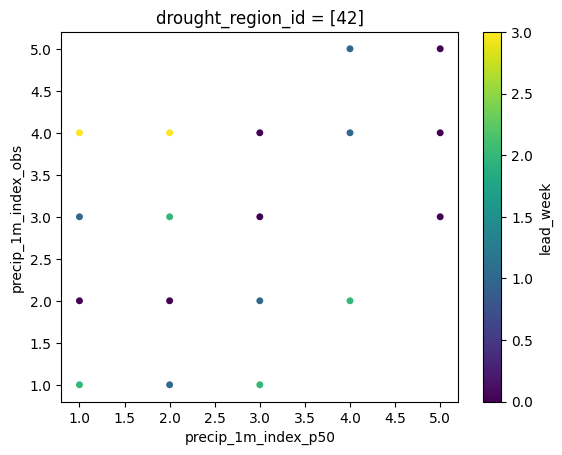

In [221]:
ds_mondays.sel(drought_region_id=[42]).plot.scatter(x="precip_1m_index_p50", y="precip_1m_index_obs", hue="lead_week")

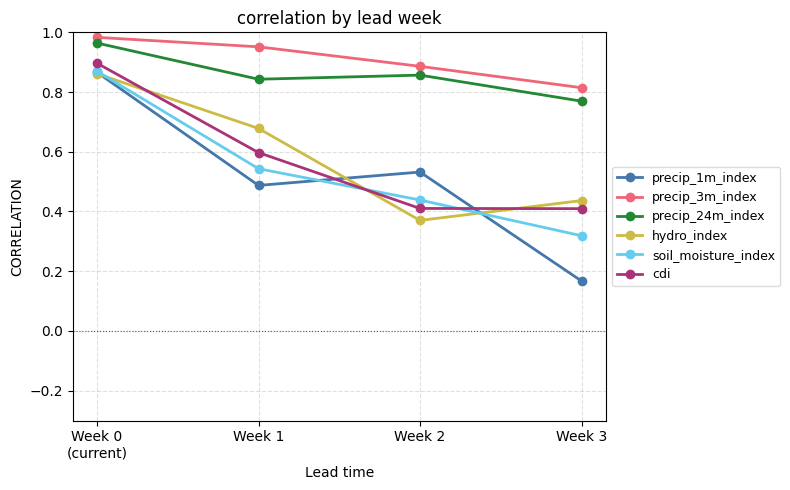

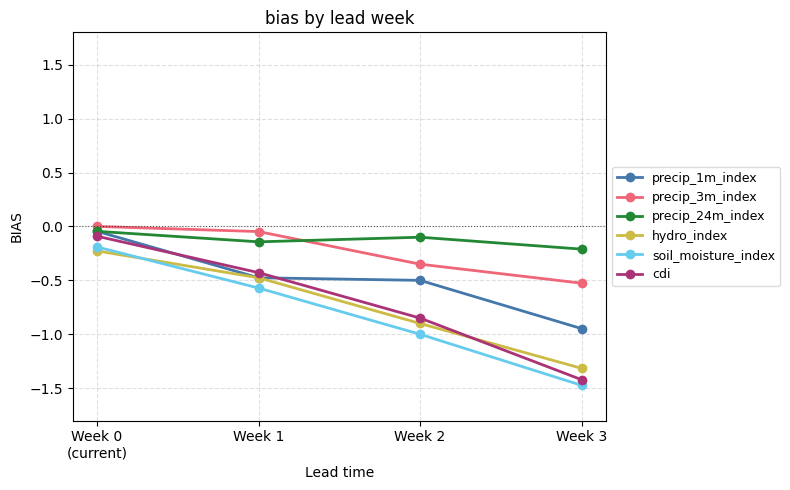

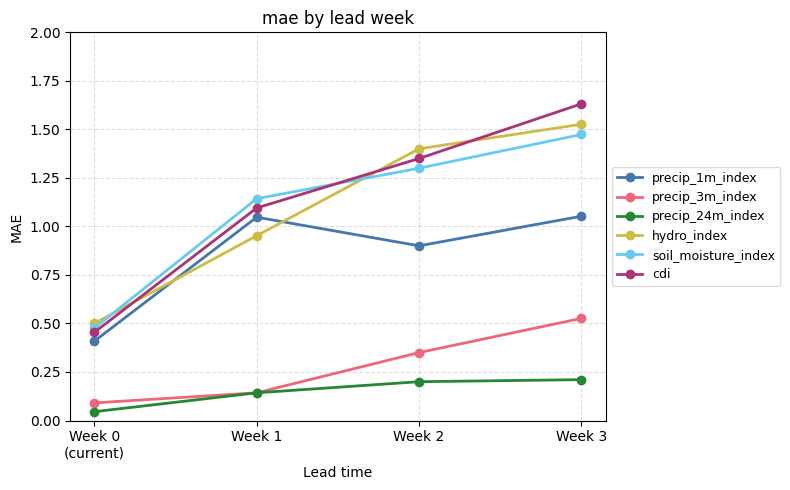

In [237]:
for _score in ["correlation","bias","mae"]:
    fig = plot_skill_vs_lead(
        ds_scores.sel(drought_region_id=42),
        variables=["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"],
        aggregate_regions=True,
        score=f"{_score}",
        title=f"{_score} by lead week",
    )
    plt.show()

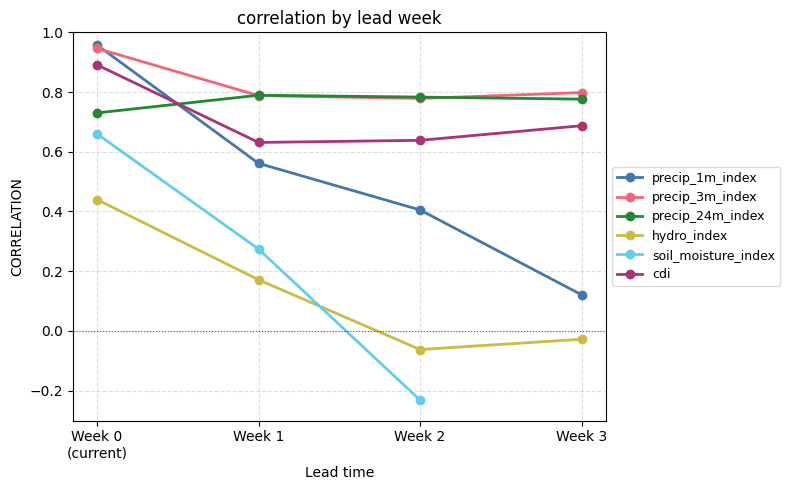

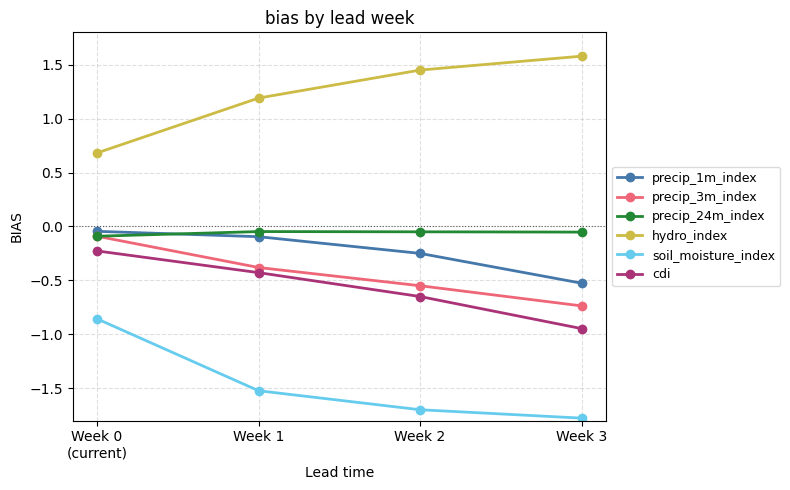

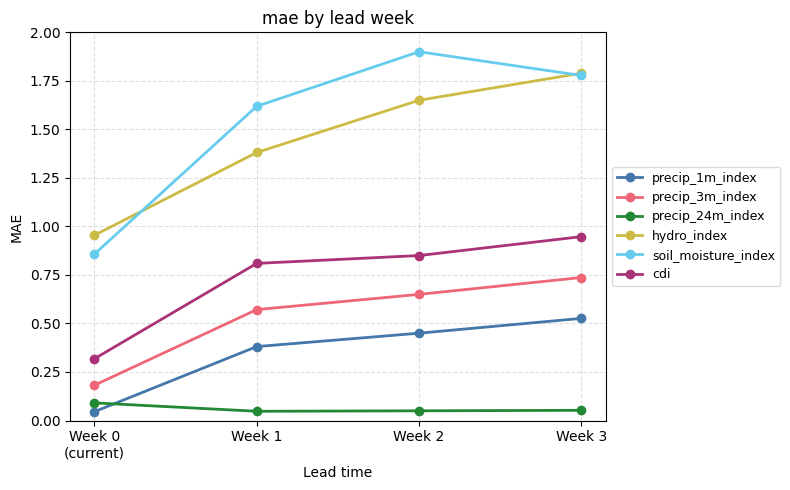

In [236]:
for _score in ["correlation","bias","mae"]:
    fig = plot_skill_vs_lead(
        ds_scores.sel(drought_region_id=60),
        variables=["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"],
        aggregate_regions=True,
        score=f"{_score}",
        title=f"{_score} by lead week",
    )
    plt.show()

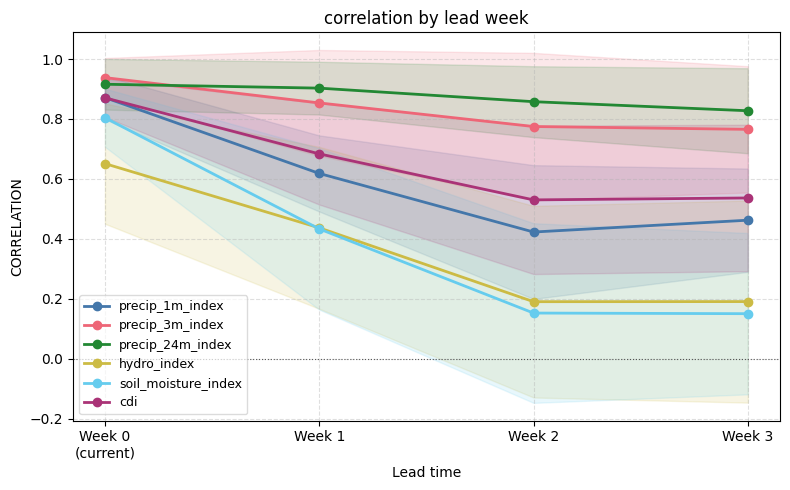

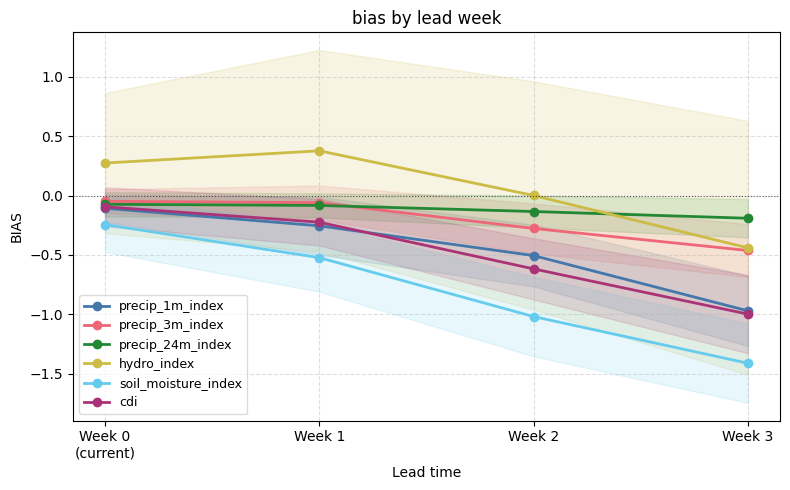

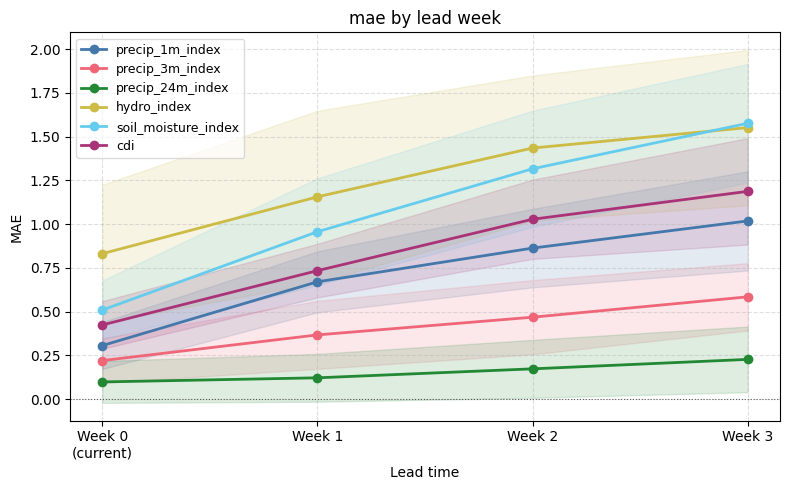

In [35]:
for _score in ["correlation","bias","mae"]:
    fig = plot_skill_vs_lead(
        ds_scores, #.sel(drought_region_id=60),
        variables=["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"],
        aggregate_regions=True,
        score=f"{_score}",
        title=f"{_score} by lead week",
    )
    plt.show()

In [36]:
ds_scores

<xarray.Dataset> Size: 110kB
Dimensions:                           (drought_region_id: 38, lead_week: 4)
Coordinates:
  * drought_region_id                 (drought_region_id) int64 304B 31 ... 68
  * lead_week                         (lead_week) int64 32B 0 1 2 3
Data variables: (12/90)
    cdi_mae                           (drought_region_id, lead_week) float64 1kB ...
    cdi_rmse                          (drought_region_id, lead_week) float64 1kB ...
    cdi_bias                          (drought_region_id, lead_week) float64 1kB ...
    cdi_correlation                   (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_mae               (drought_region_id, lead_week) float64 1kB ...
    precip_1m_index_rmse              (drought_region_id, lead_week) float64 1kB ...
    ...                                ...
    soil_moisture_ufc_mae             (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_rmse            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_bias            (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_correlation     (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_pinball         (drought_region_id, lead_week) float64 1kB ...
    soil_moisture_ufc_interval_score  (drought_region_id, lead_week) float64 1kB ...
Attributes:
    source:            drought_forecast_eval
    variables_scored:  cdi,precip_1m_index,precip_3m_index,precip_24m_index,h...
    scores_computed:   mae,rmse,bias,correlation,pinball,interval_score
    cdi_threshold:     2
    reference_type:    climatology

/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(re

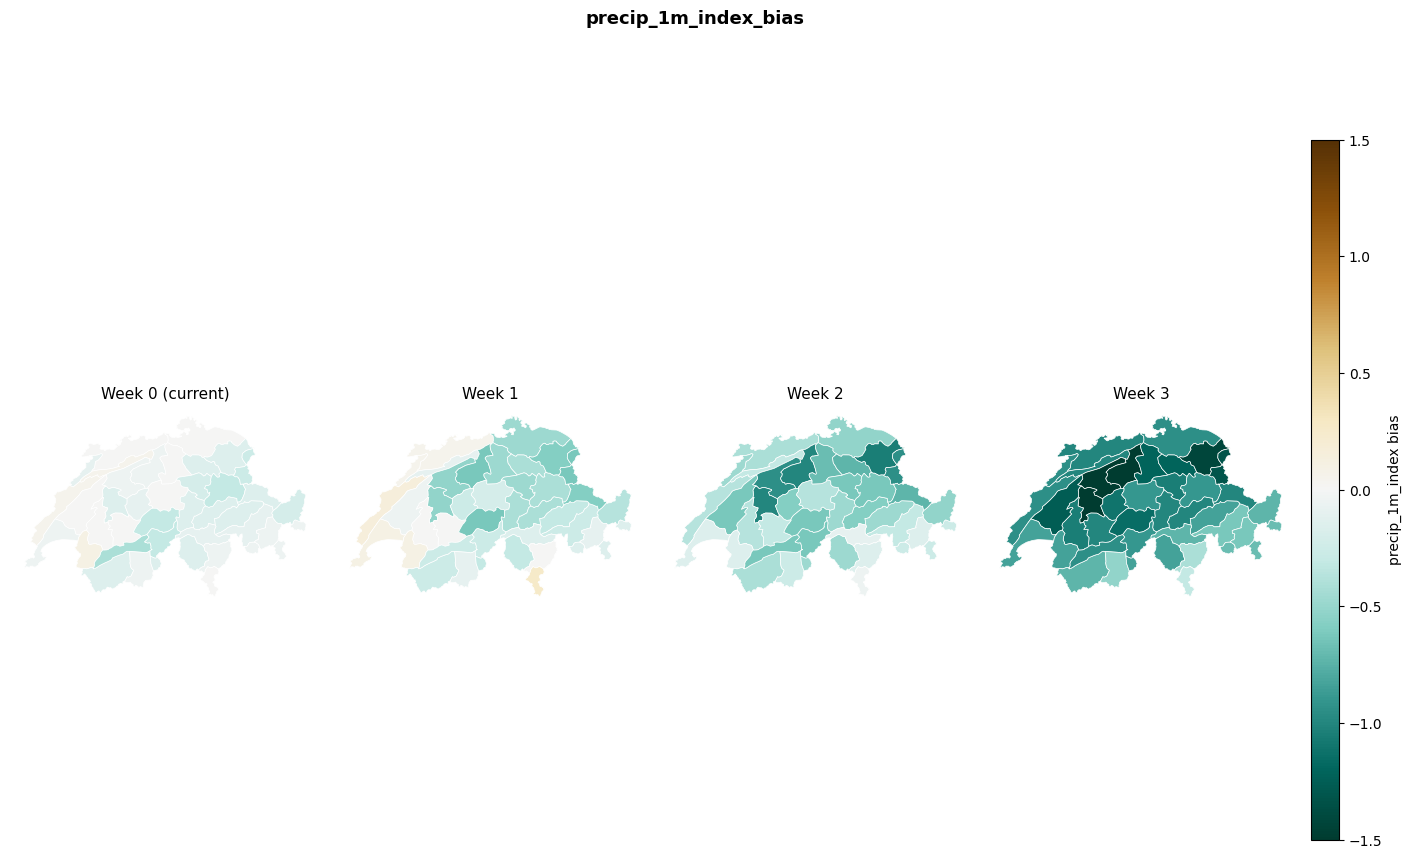

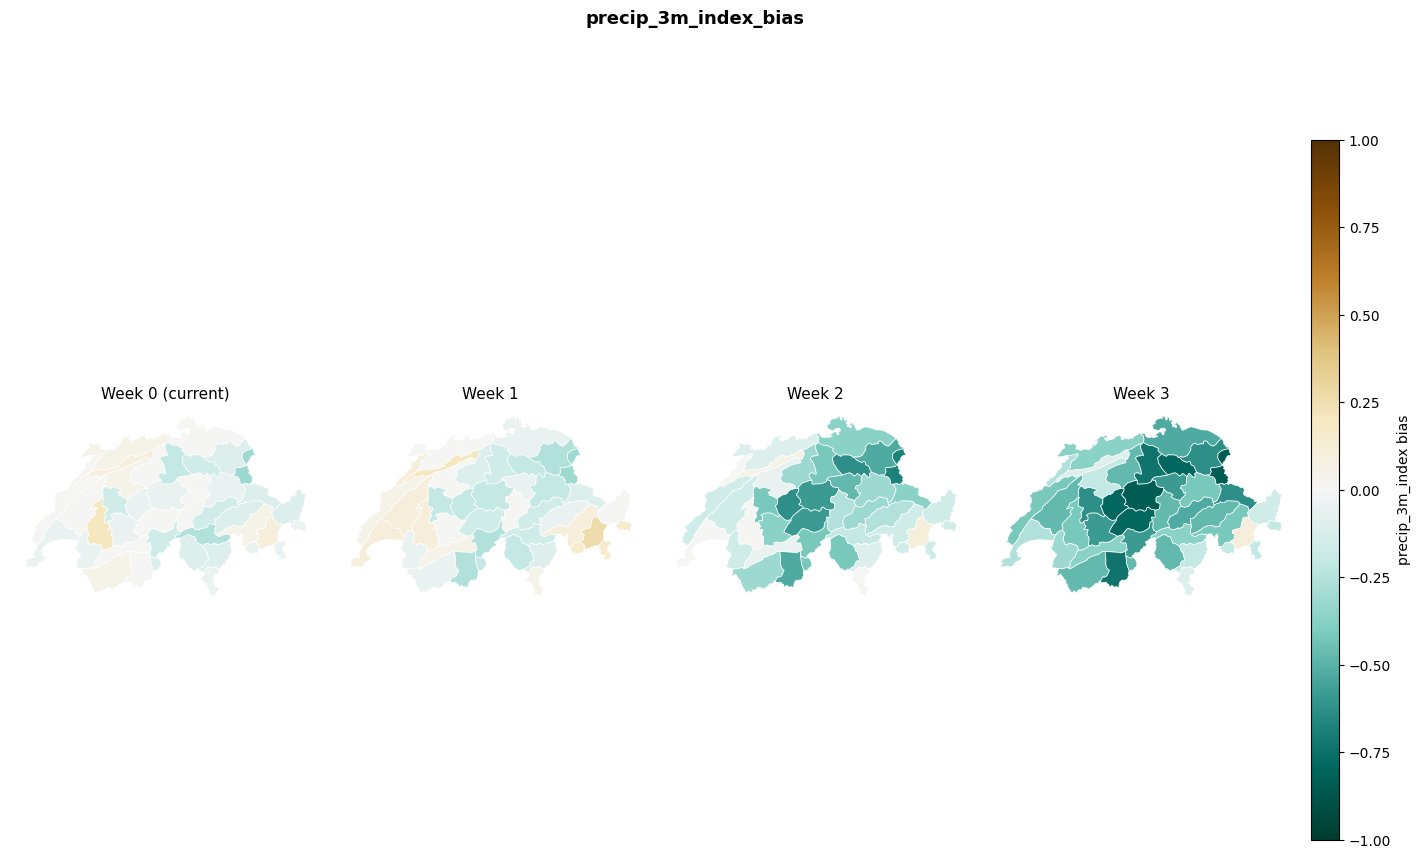

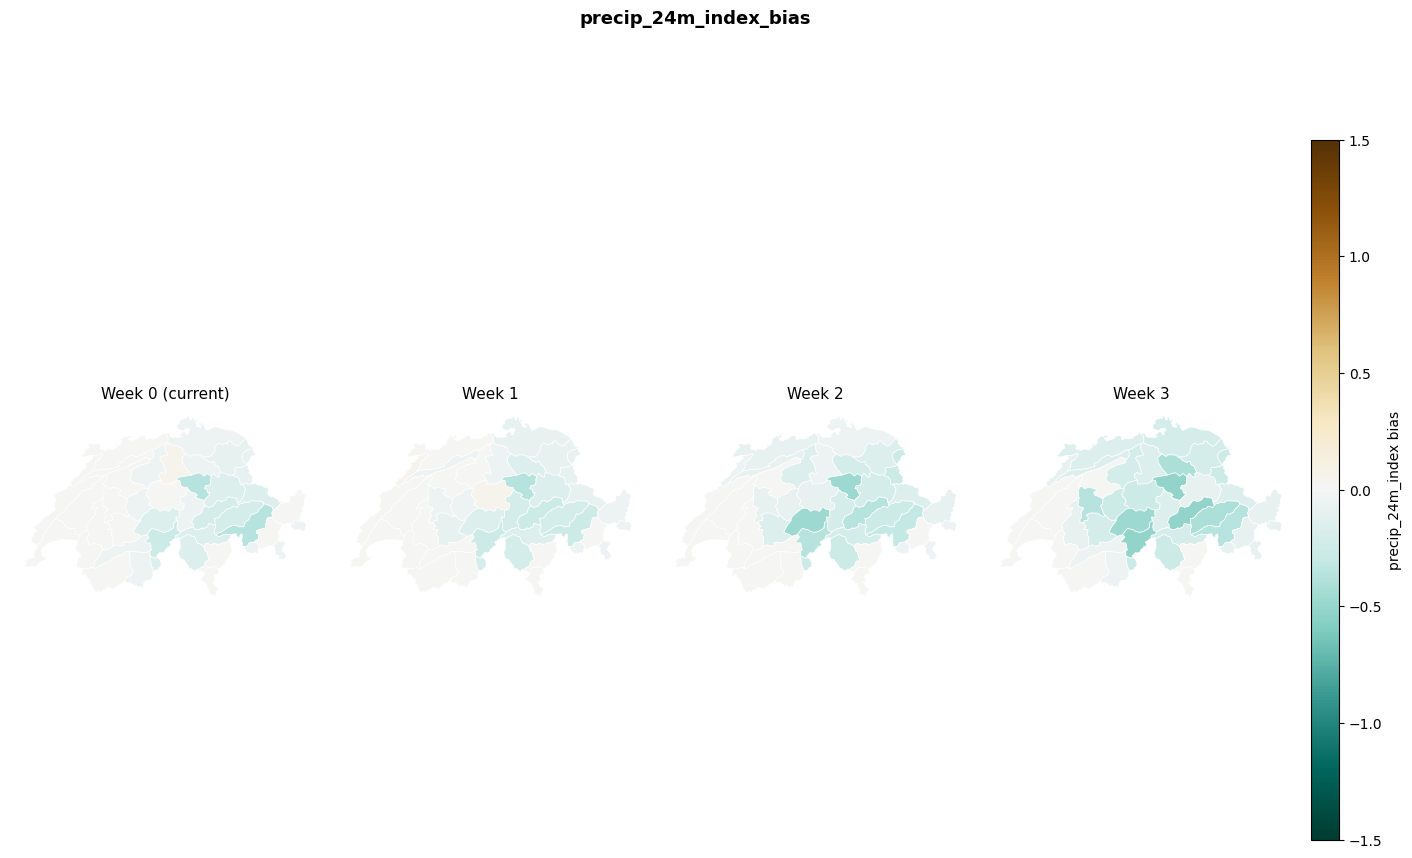

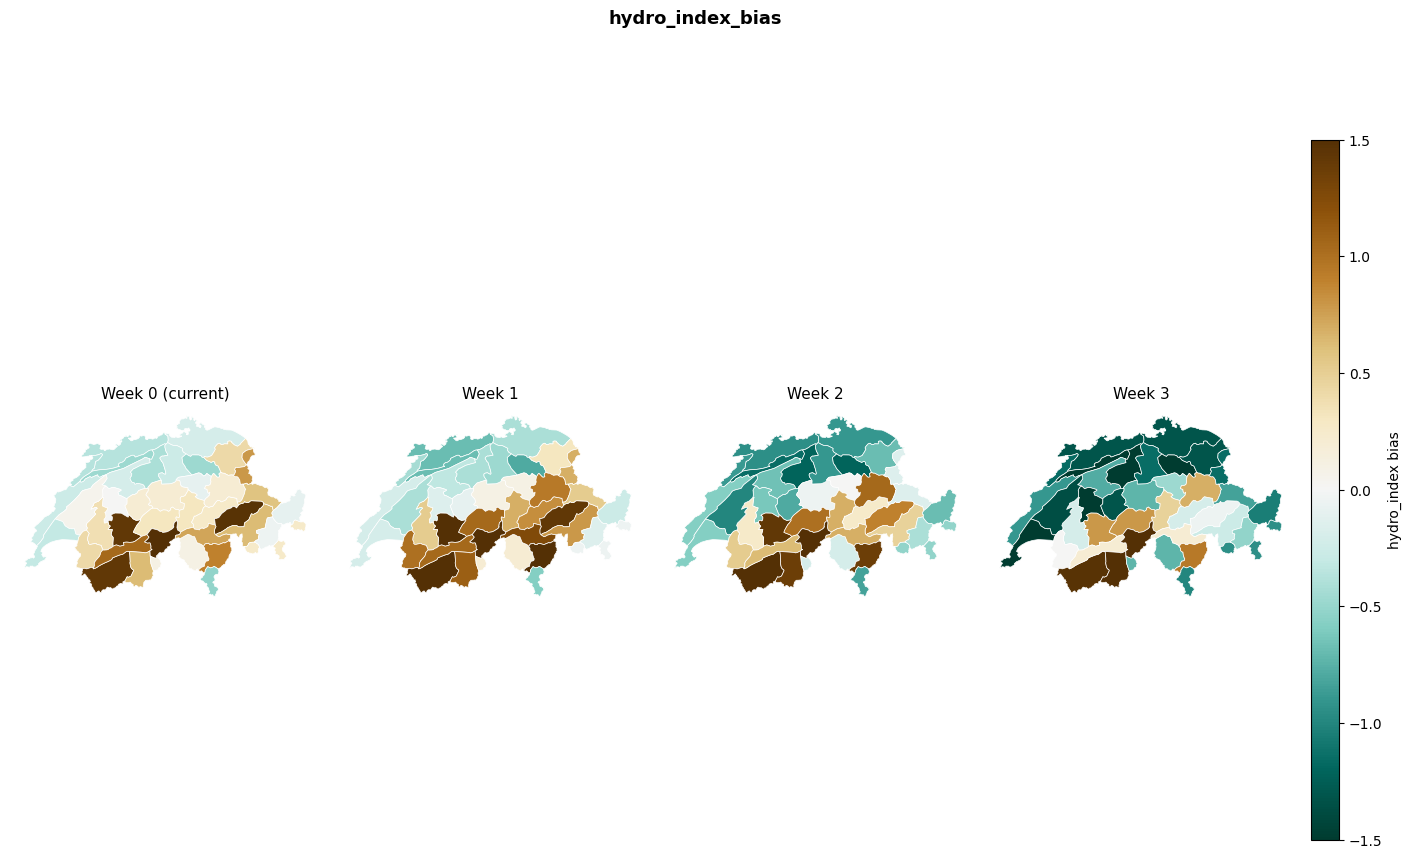

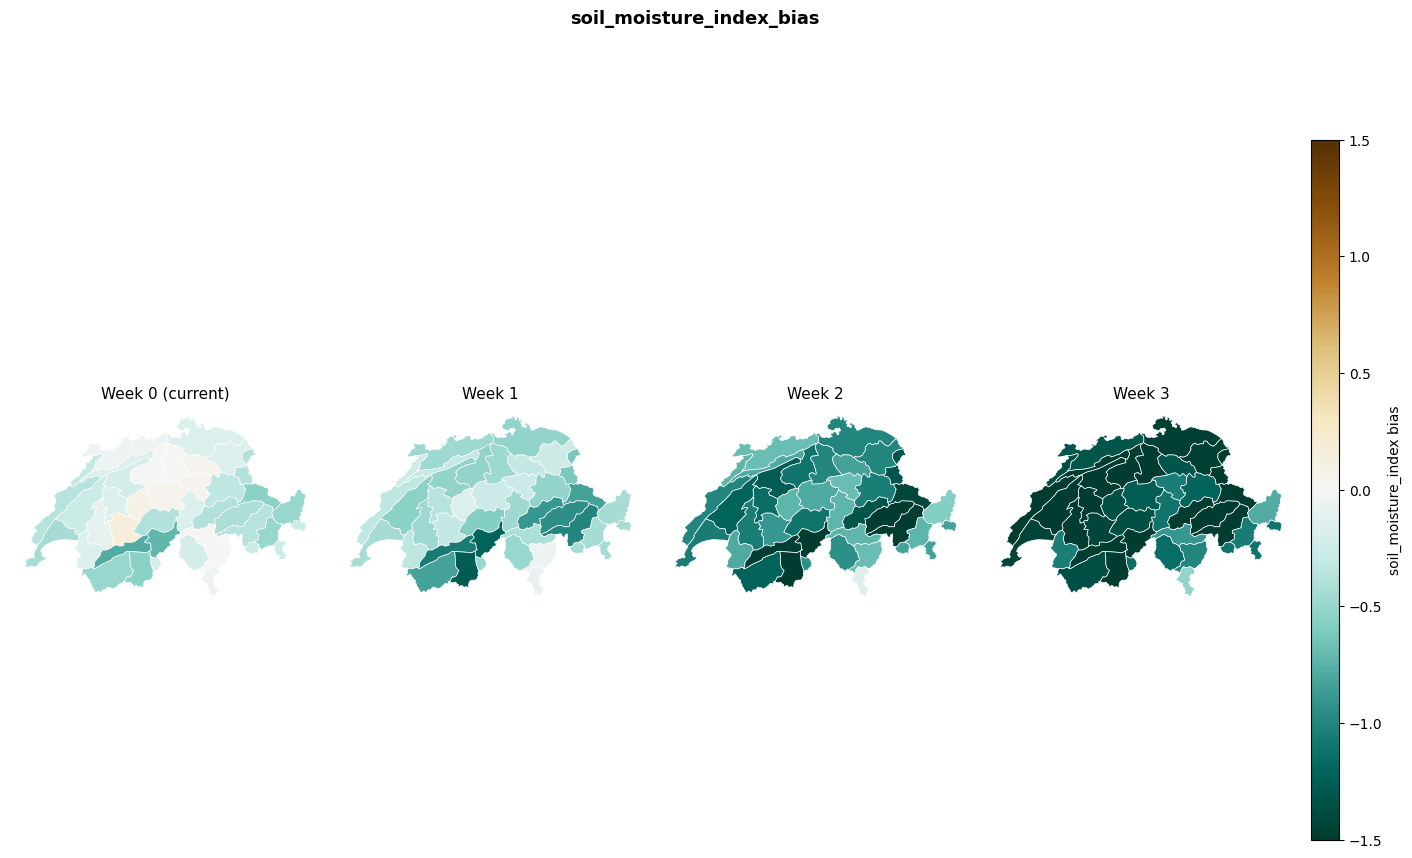

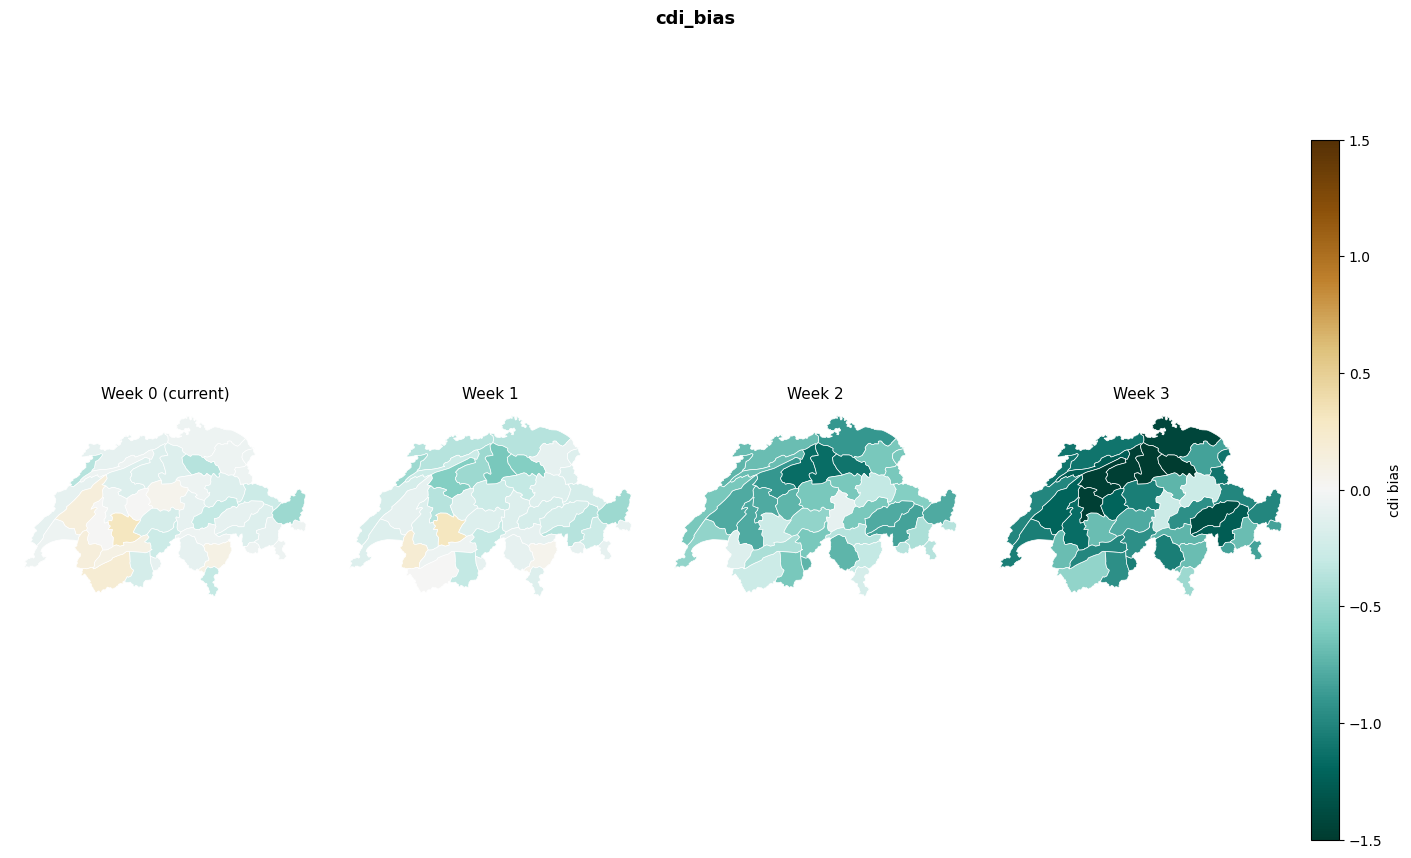

In [37]:
# Regional map (requires shapefile; falls back to bar chart if not provided)
from drought_forecast_eval.visualization import plot_region_map


score = "bias"

_vmin, _vmax = -1.5, 1.5

fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_1m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=_vmin,
    vmax=_vmax
)
fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_3m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=-1,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_24m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=_vmin,
    vmax=_vmax
)
fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"hydro_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=_vmin,
    vmax=_vmax
)
fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"soil_moisture_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=_vmin,
    vmax=_vmax
)


fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"cdi_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="BrBG_r",
    vmin=_vmin,
    vmax=_vmax
)


plt.show()

/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(re

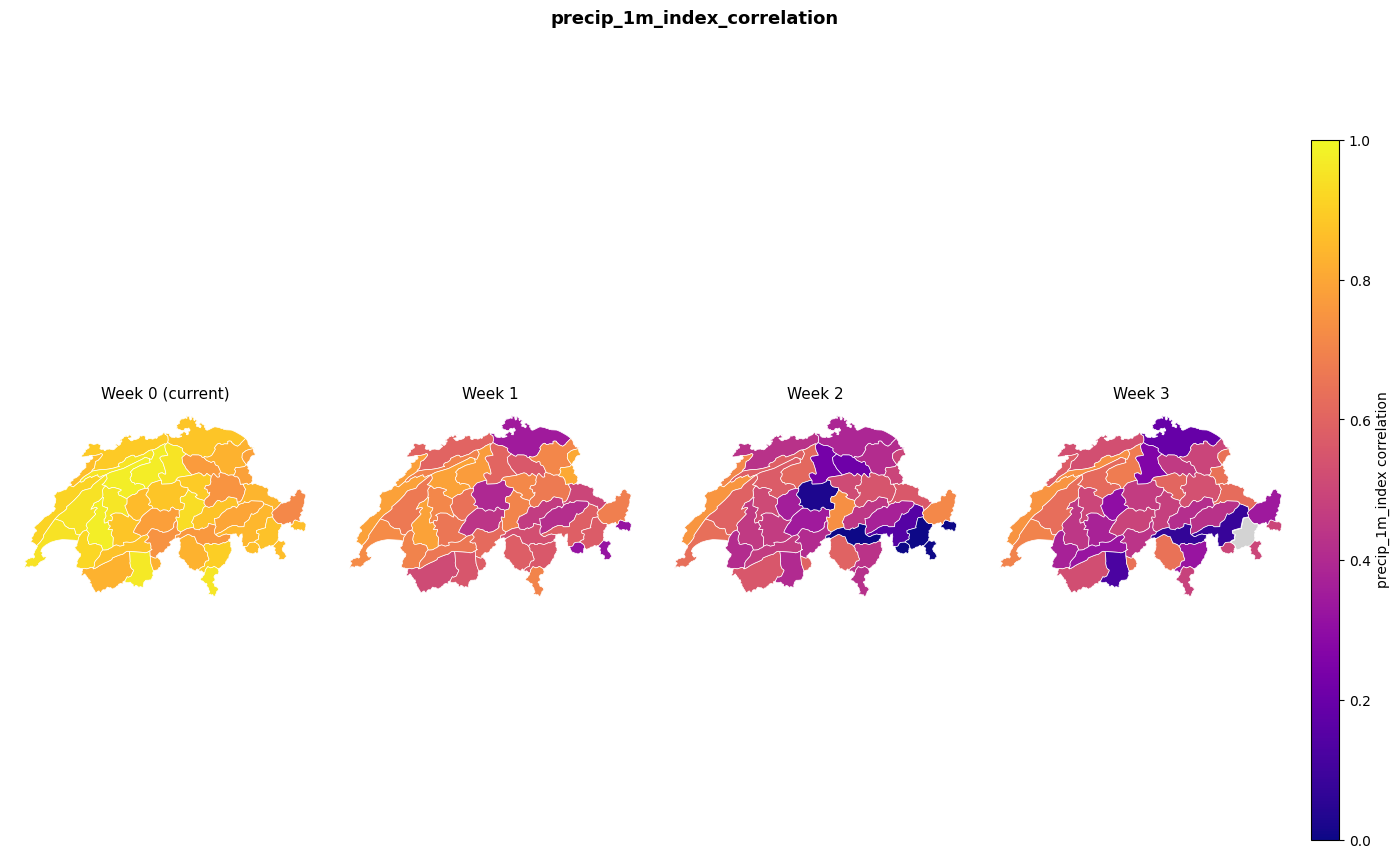

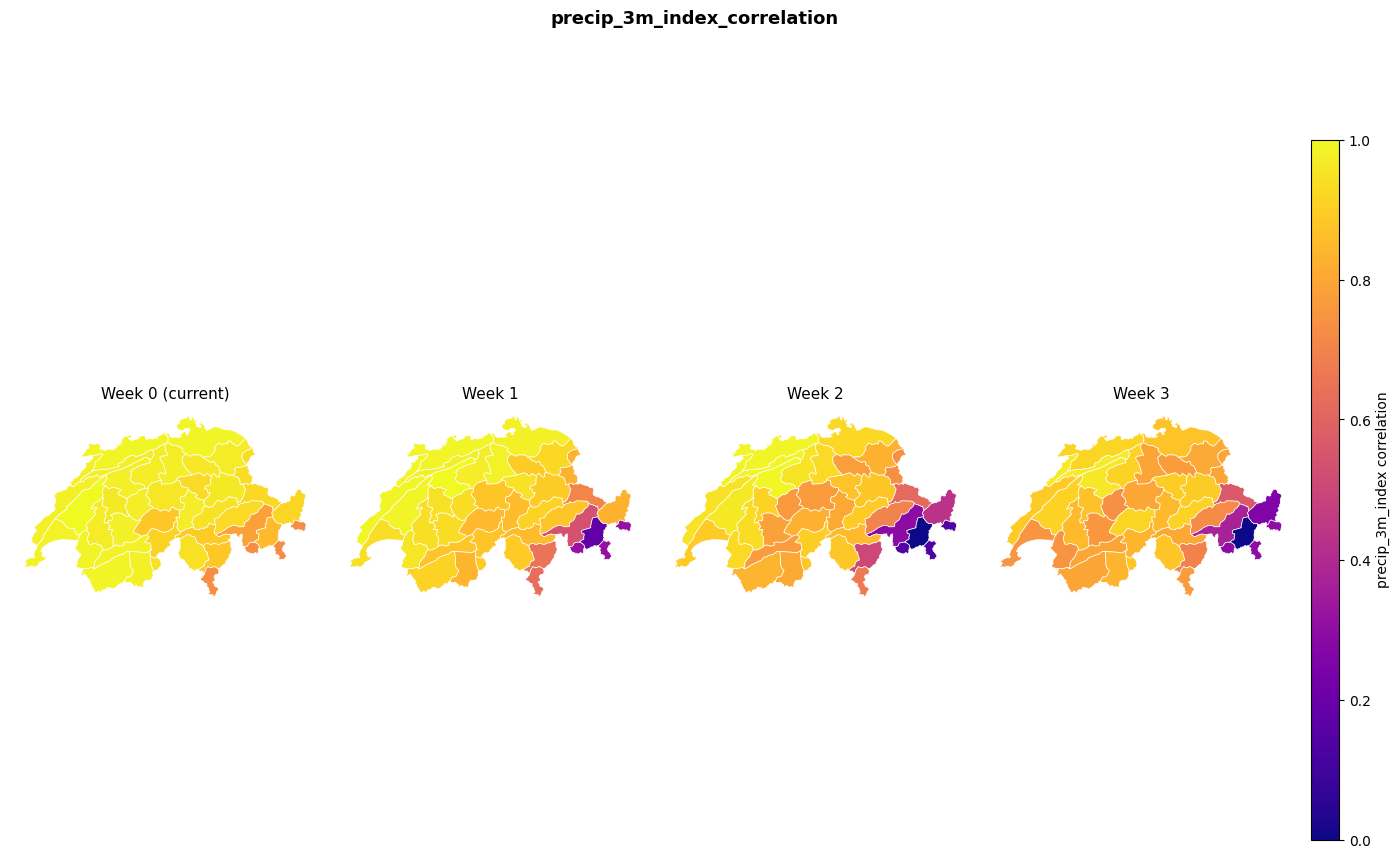

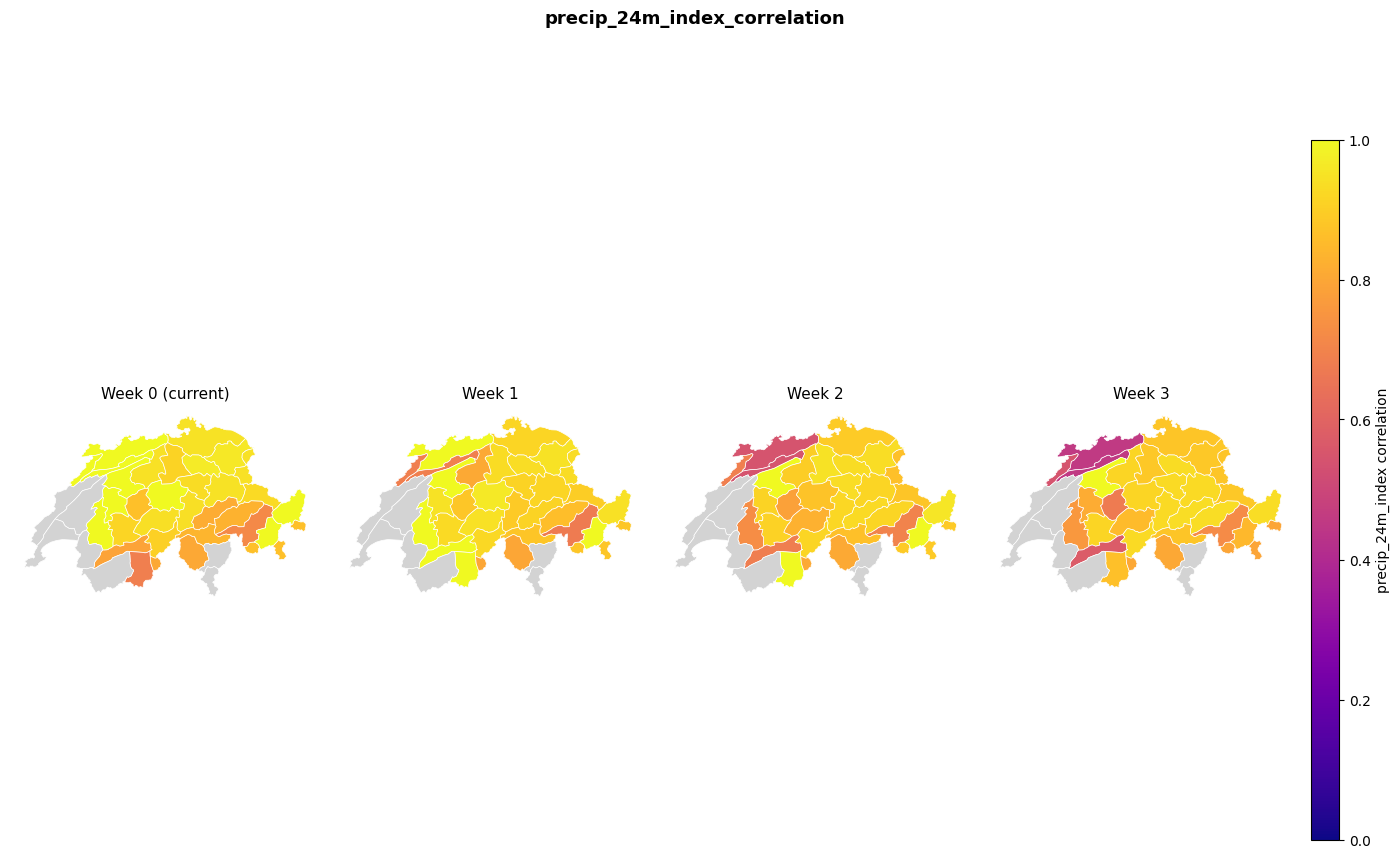

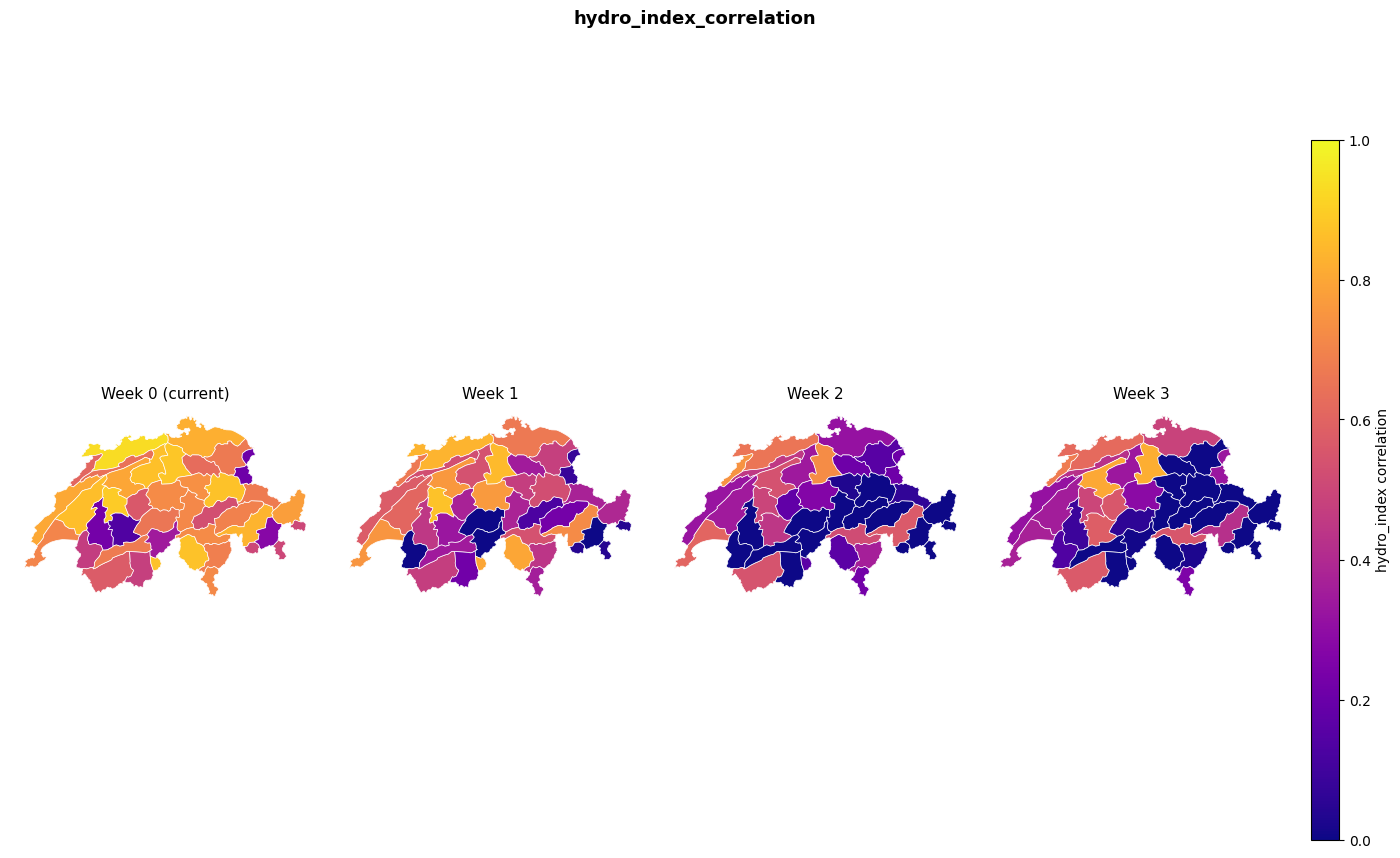

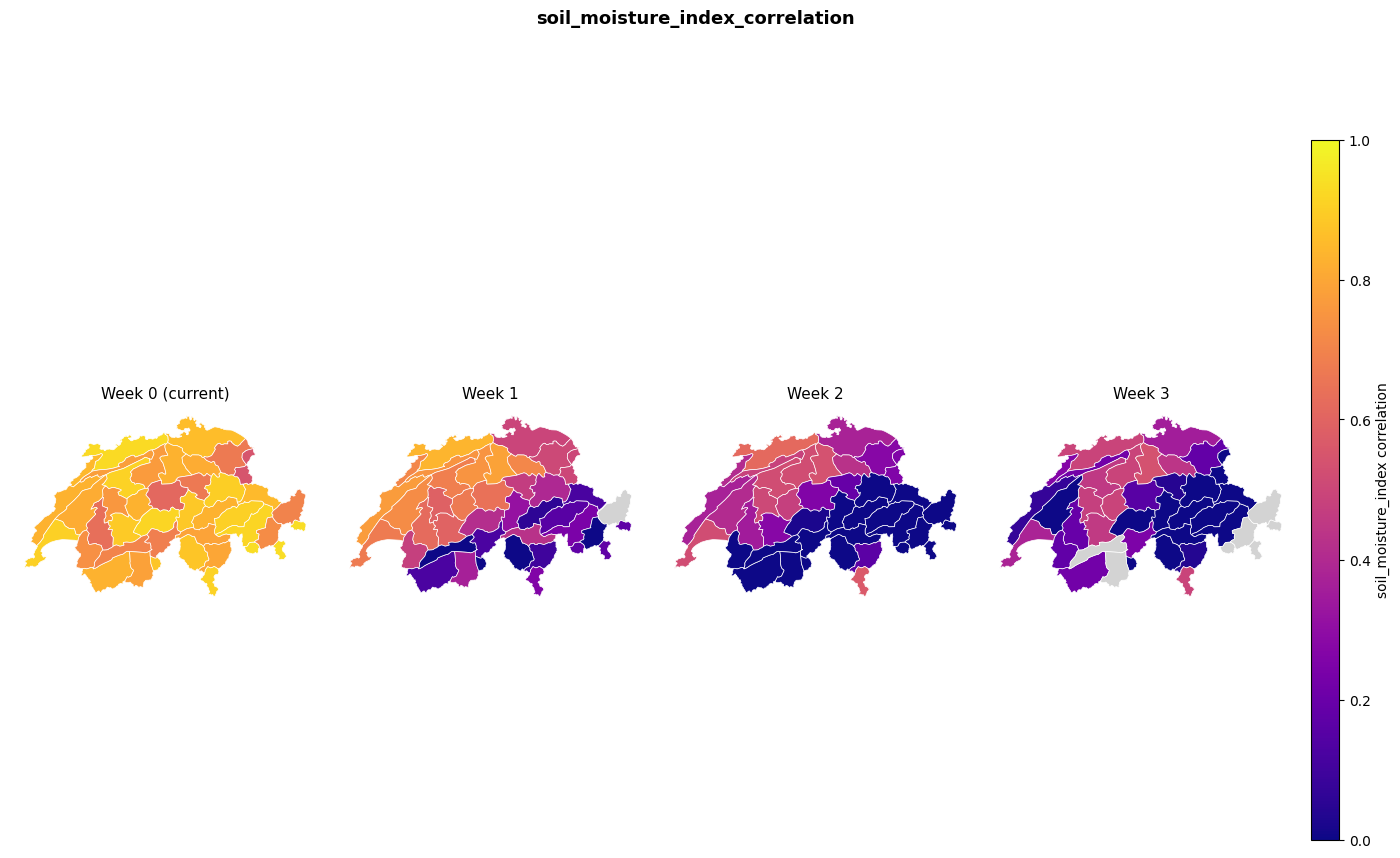

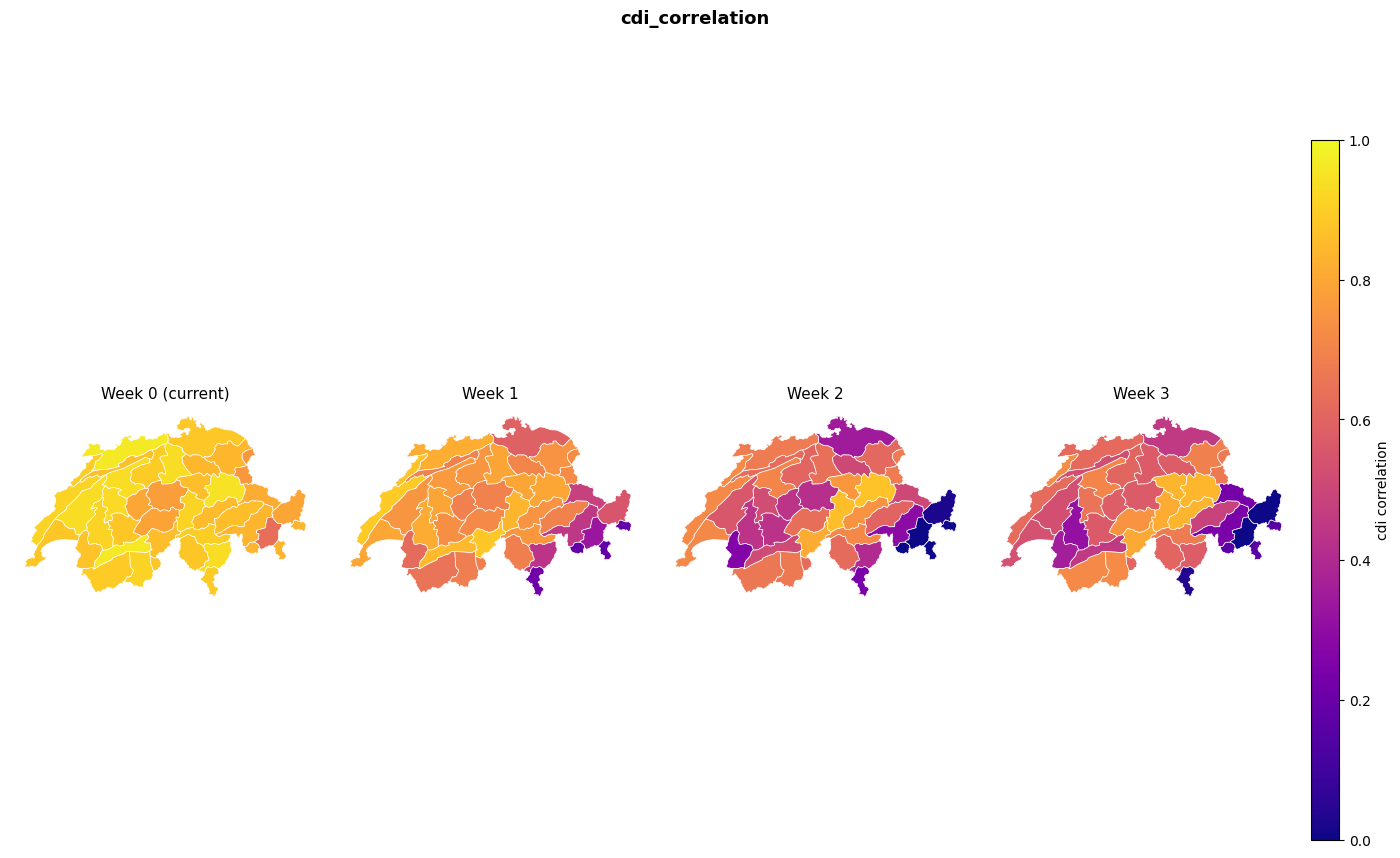

In [47]:
# Regional map (requires shapefile; falls back to bar chart if not provided)
from drought_forecast_eval.visualization import plot_region_map


score = "correlation"

_vmin, _vmax = 0,1

cmap = "plasma"

fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_1m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap=cmap,
    vmin=_vmin,
    vmax=_vmax
)
fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_3m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap=cmap,
    vmin=_vmin,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"precip_24m_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap=cmap,
    vmin=_vmin,
    vmax=_vmax
)
fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"hydro_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap=cmap,
    vmin=_vmin,
    vmax=_vmax
)
fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"soil_moisture_index_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap=cmap,
    vmin=_vmin,
    vmax=_vmax
)


fig4 = plot_region_map(
    ds_scores=ds_scores,
    score_variable=f"cdi_{score}",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap=cmap,
    vmin=_vmin,
    vmax=_vmax
)


plt.show()

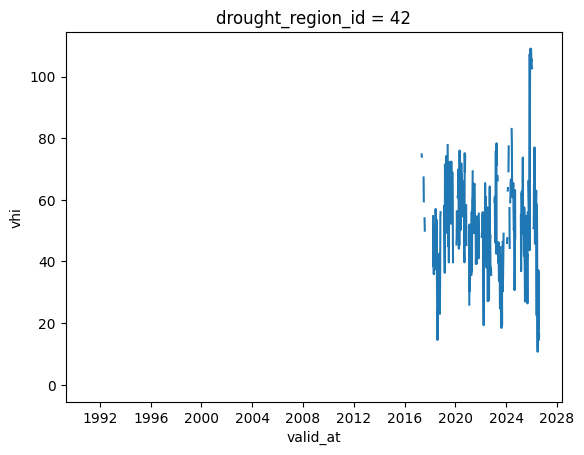

In [241]:
ds_obs.vhi.sel(drought_region_id=42).plot(x="valid_at")

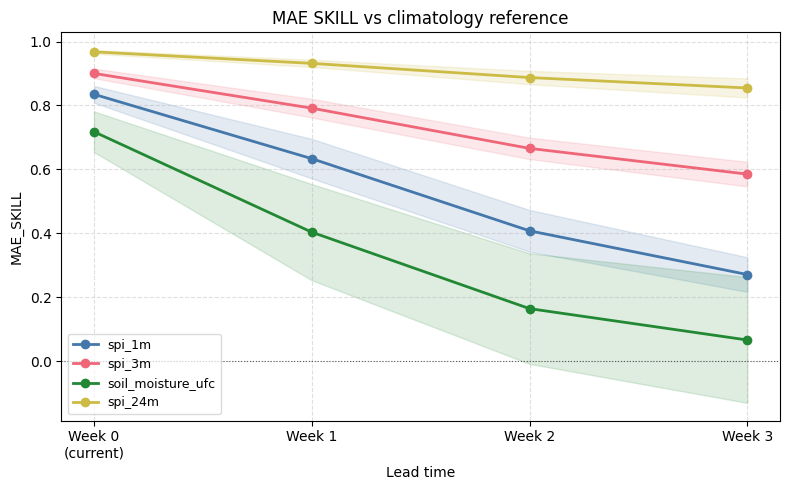

In [38]:
# RPSS (requires reference forecast)
ds_scores_w_skill = compute_scores(
    ds_merged,
    variables=["spi_1m", "spi_3m", "spi_24m", "soil_moisture_ufc", "hydro_index"],
    scores=["mae_skill"],
    ds_ref=ds_ref_clim,
)

fig2 = plot_skill_vs_lead(
    ds_scores_w_skill,
    variables=["spi_1m", "spi_3m","soil_moisture_ufc","spi_24m"],
    score="mae_skill",
    zero_line=True,
    title="MAE SKILL vs climatology reference",
)
plt.show()

In [39]:
ds_merged

<xarray.Dataset> Size: 27MB
Dimensions:                  (forecast_reference_time: 376,
                              drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time  (forecast_reference_time) datetime64[ns] 3kB 202...
  * drought_region_id        (drought_region_id) int64 304B 31 32 33 ... 67 68
  * lead_week                (lead_week) int64 32B 0 1 2 3
    valid_at                 (forecast_reference_time, drought_region_id, lead_week) datetime64[ns] 457kB ...
Data variables: (12/57)
    cdi_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_3m_index_p50      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_24m_index_p50     (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    hydro_index_p50          (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_index_p50  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    ...                       ...
    spi_3m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    spi_6m_obs               (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    spi_12m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    spi_24m_obs              (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_obs    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    vhi_obs                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
Attributes:
    source:       drought_forecast_eval
    description:  Swiss drought forecast archive

/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])
/home/ima/work/projects/drought-forecast-eval/drought_forecast_eval/visualization/region_map.py:249: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.94, 1])


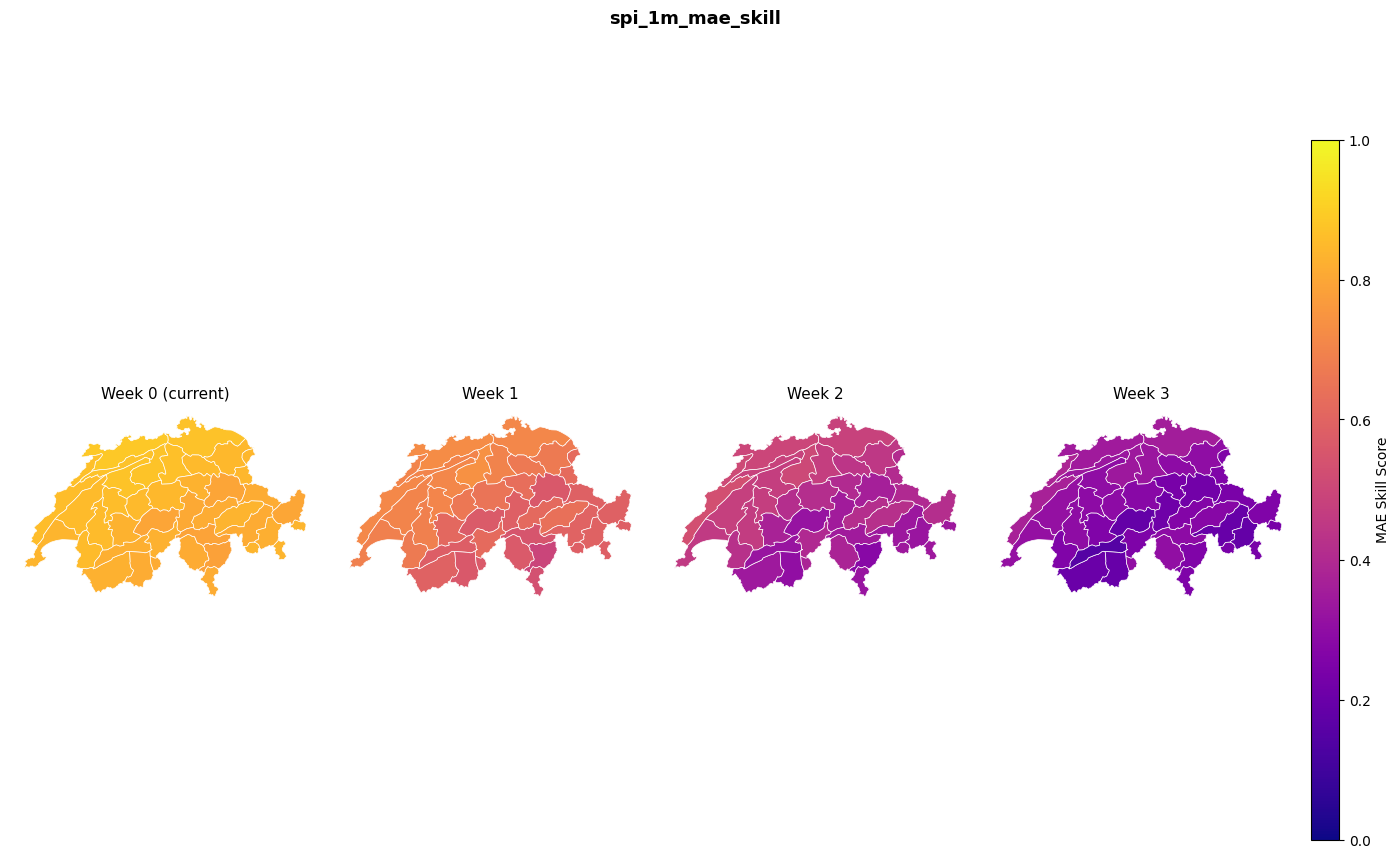

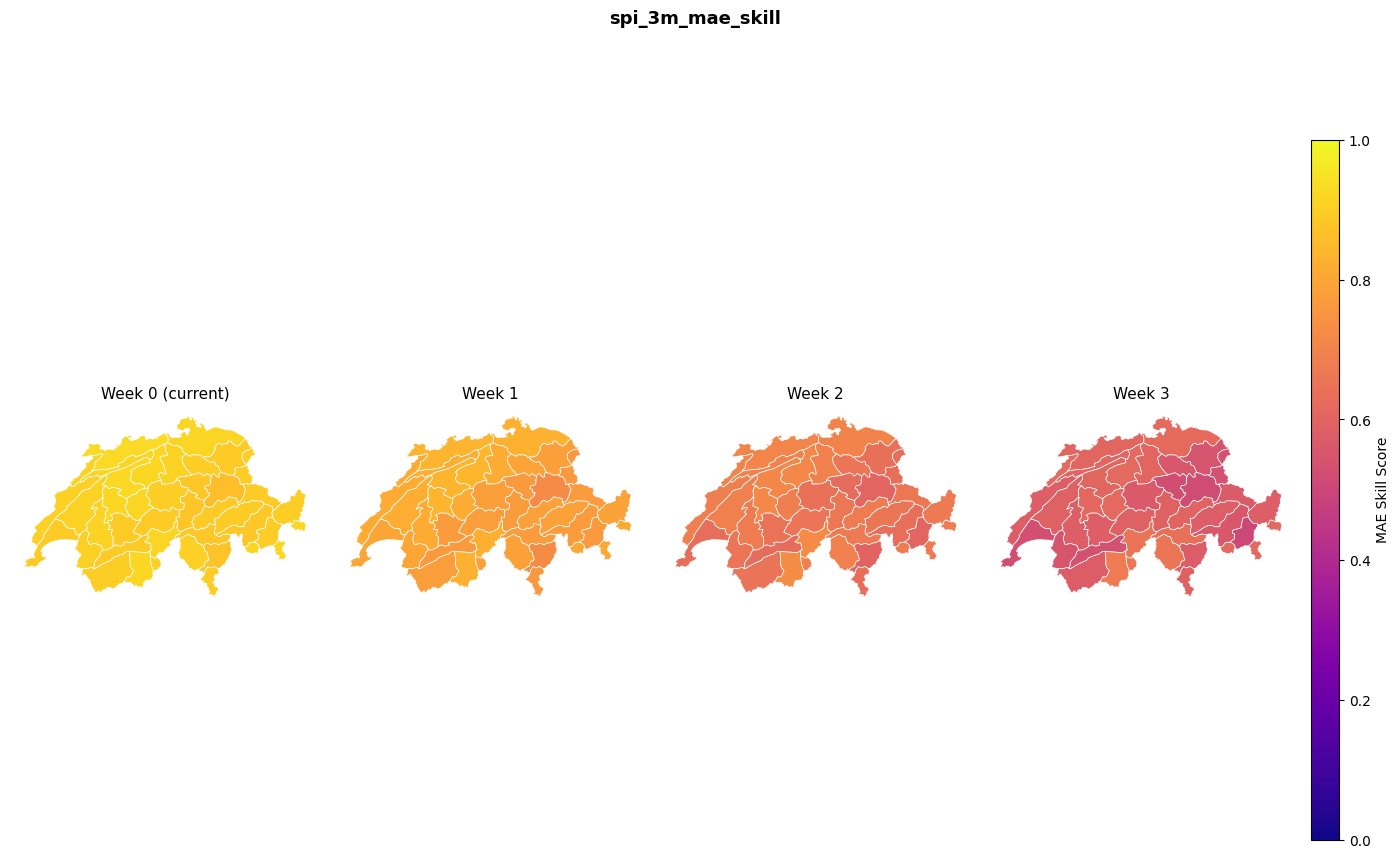

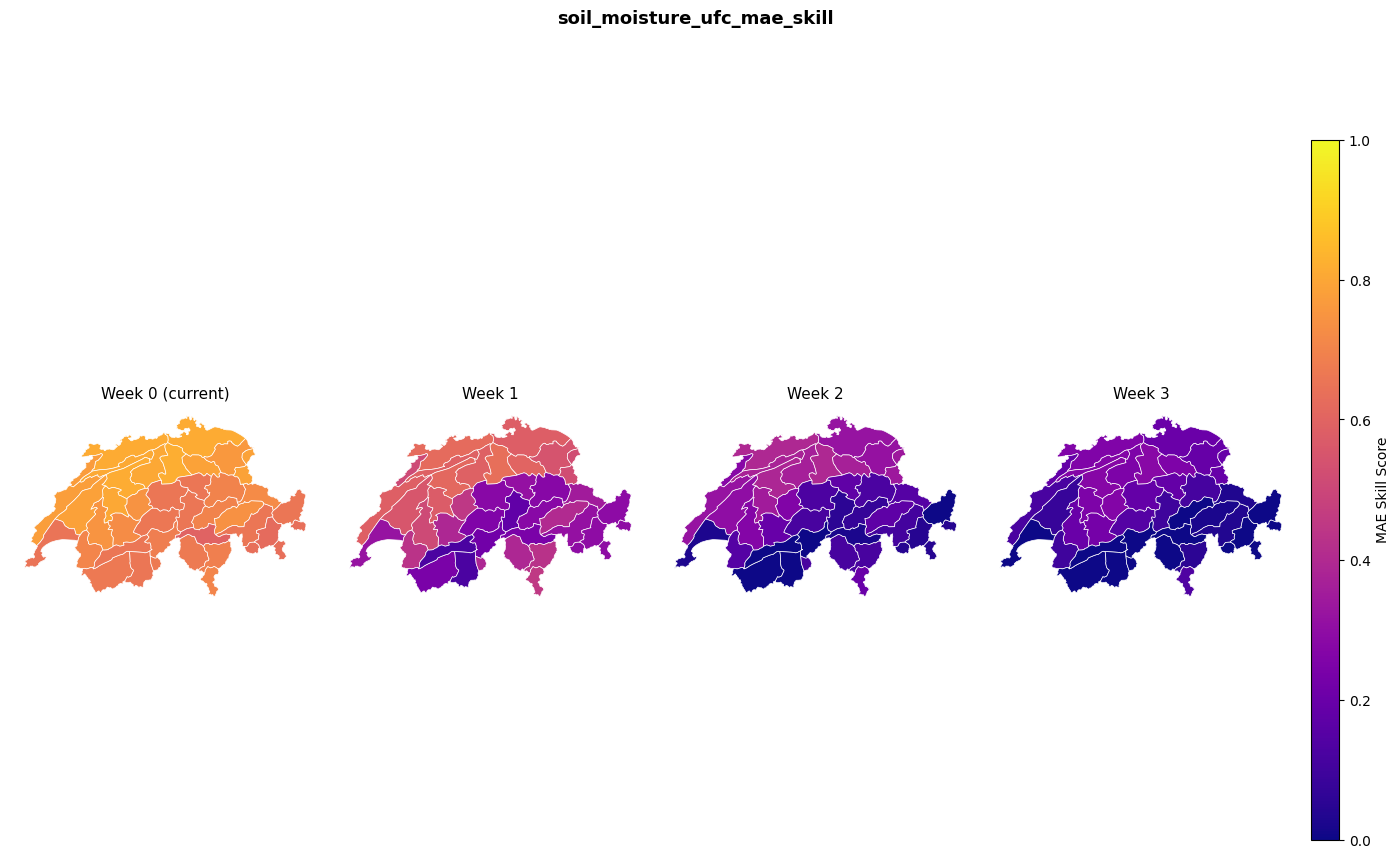

In [40]:
# Regional map (requires shapefile; falls back to bar chart if not provided)
from drought_forecast_eval.visualization import plot_region_map

fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="spi_1m_mae_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="spi_3m_mae_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)
fig3 = plot_region_map(
    ds_scores_w_skill,
    score_variable="soil_moisture_ufc_mae_skill",
    shapefile_path=SHAPEFILE,
    lead_weeks=[0, 1, 2, 3],
    cmap="plasma",
    vmin=0,
    vmax=1
)


plt.show()

In [41]:
ds_ref_clim

<xarray.Dataset> Size: 25MB
Dimensions:                      (forecast_reference_time: 376,
                                  drought_region_id: 38, lead_week: 4)
Coordinates:
  * forecast_reference_time      (forecast_reference_time) datetime64[ns] 3kB ...
  * drought_region_id            (drought_region_id) int64 304B 31 32 ... 67 68
  * lead_week                    (lead_week) int64 32B 0 1 2 3
Data variables: (12/54)
    cdi_ref_p10                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    cdi_ref_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    cdi_ref_p90                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_ref_p10      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_ref_p50      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    precip_1m_index_ref_p90      (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    ...                           ...
    soil_moisture_ufc_ref_p10    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_ref_p50    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    soil_moisture_ufc_ref_p90    (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    vhi_ref_p10                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    vhi_ref_p50                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
    vhi_ref_p90                  (forecast_reference_time, drought_region_id, lead_week) float64 457kB ...
Attributes:
    reference_type:  climatology
    week_window:     4

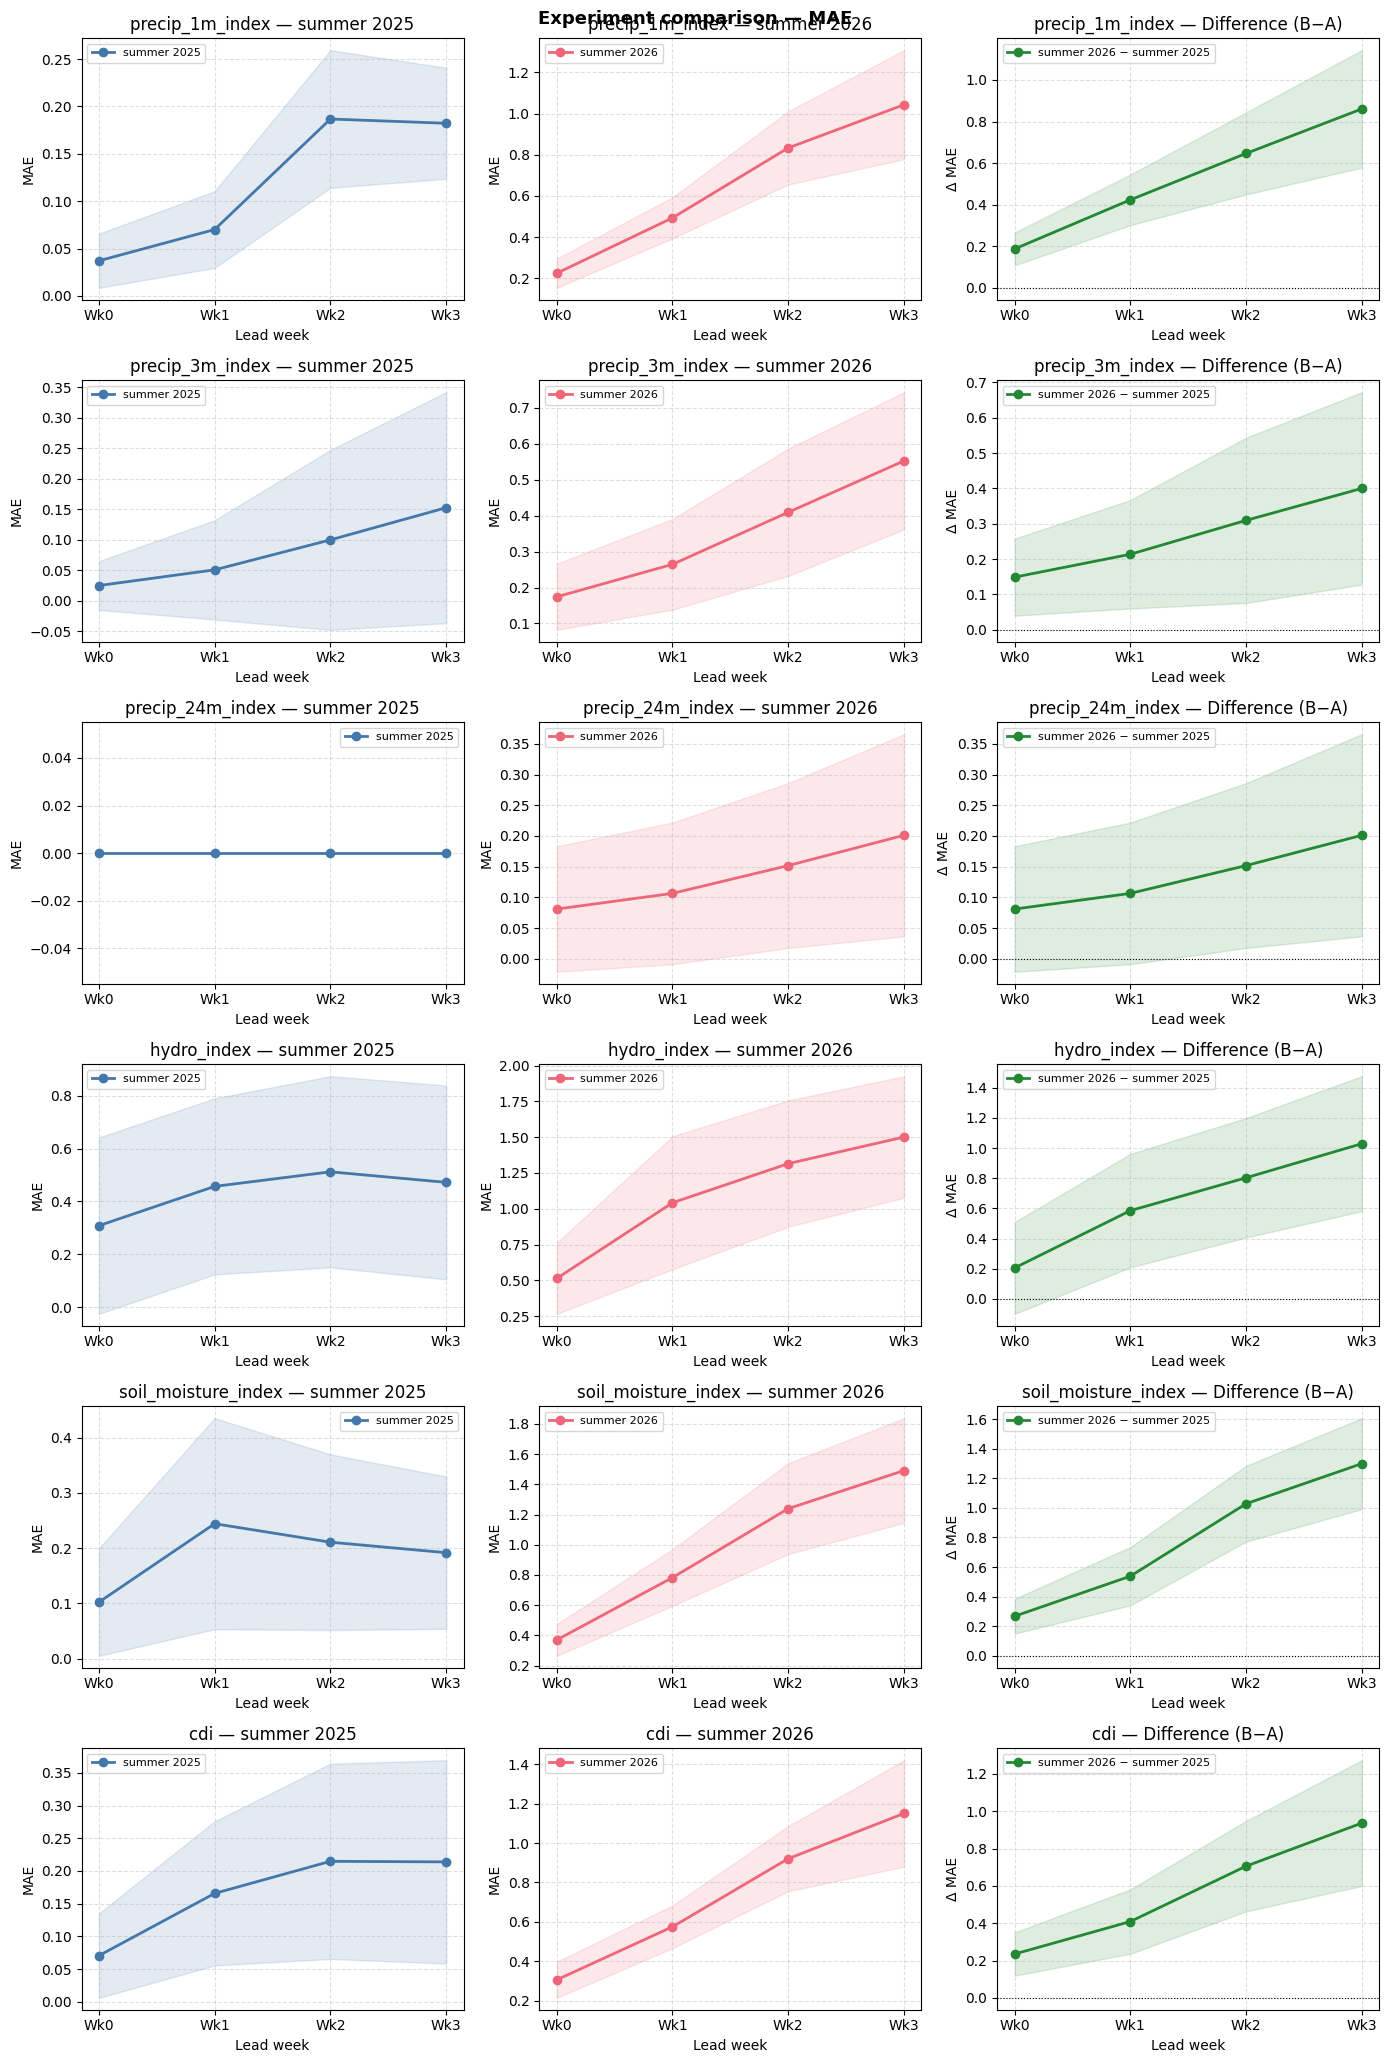

In [48]:
# Experiment comparison: period A vs period B
from drought_forecast_eval.visualization import plot_experiment_diff

# Example: compare first half vs second half of the year
DATE_RANGE_A = ("2025-07-01", "2025-10-29")
DATE_RANGE_B = ("2026-03-01", "2026-07-30")

ds_merged_a = ds_merged.sel(forecast_reference_time=slice(*DATE_RANGE_A))
ds_merged_b = ds_merged.sel(forecast_reference_time=slice(*DATE_RANGE_B))

cdi_vars = ["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"]
scores = ["mae","correlation", "bias"]

ds_scores_a = compute_scores(ds_merged_a, variables=cdi_vars, scores=scores, ds_ref=ds_ref_clim)
ds_scores_b = compute_scores(ds_merged_b, variables=cdi_vars, scores=scores, ds_ref=ds_ref_clim)

fig4 = plot_experiment_diff(
    ds_scores_a, ds_scores_b,
    variables=cdi_vars,
    score="mae",
    label_a="summer 2025",
    label_b="summer 2026",
)
plt.show()

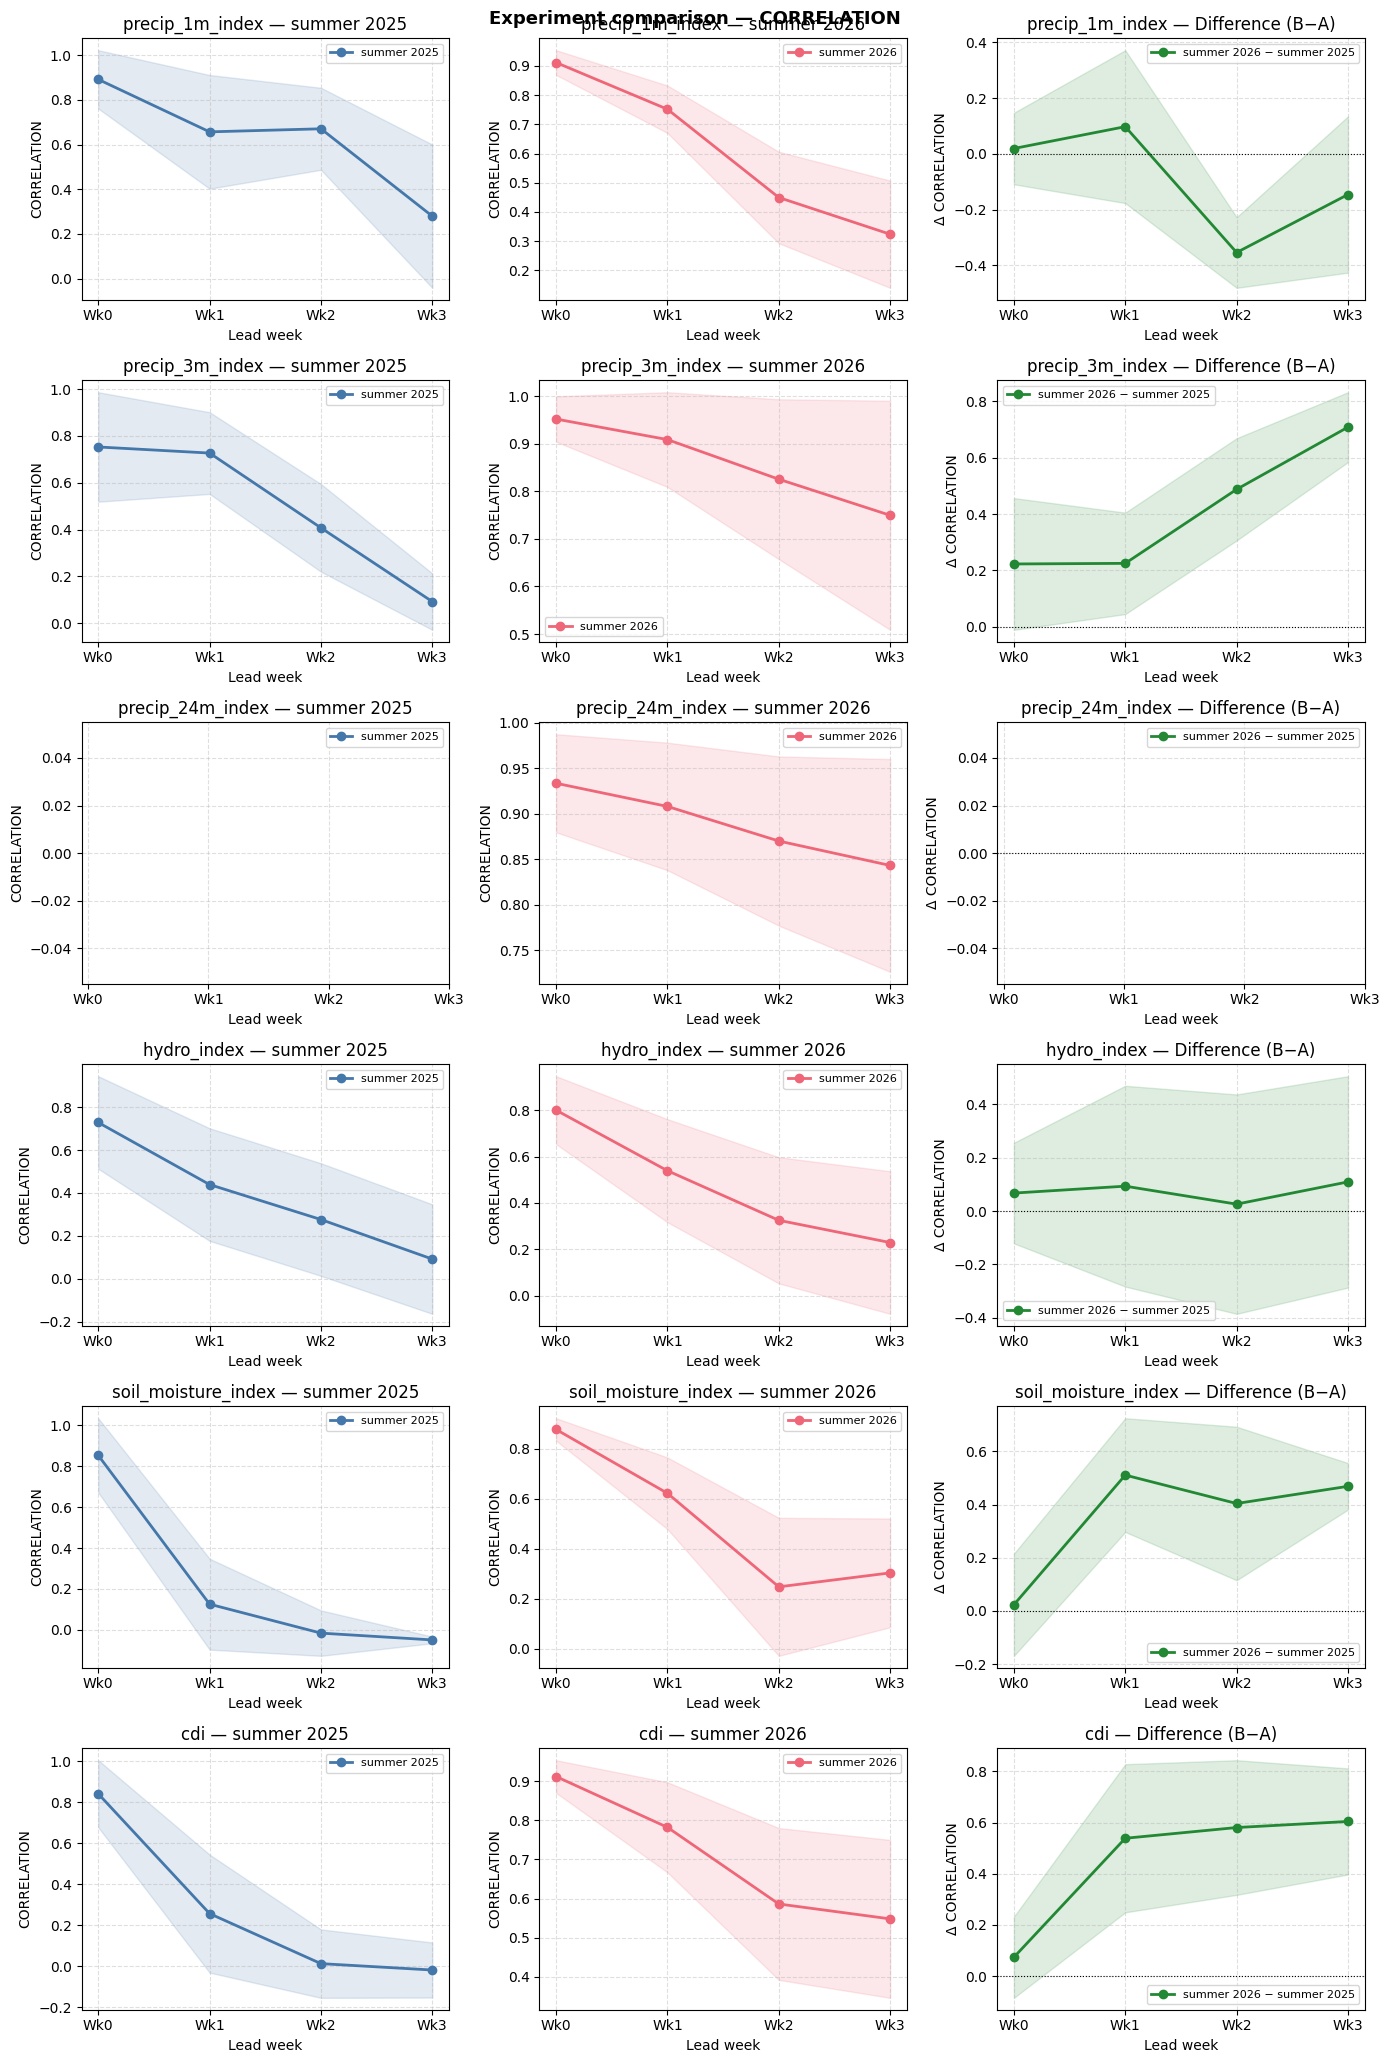

In [49]:
# Experiment comparison: period A vs period B
from drought_forecast_eval.visualization import plot_experiment_diff

# Example: compare first half vs second half of the year
DATE_RANGE_A = ("2025-07-01", "2025-10-29")
DATE_RANGE_B = ("2026-03-01", "2026-07-30")

ds_merged_a = ds_merged.sel(forecast_reference_time=slice(*DATE_RANGE_A))
ds_merged_b = ds_merged.sel(forecast_reference_time=slice(*DATE_RANGE_B))

cdi_vars = ["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"]
scores = ["mae","correlation", "bias"]

ds_scores_a = compute_scores(ds_merged_a, variables=cdi_vars, scores=scores, ds_ref=ds_ref_clim)
ds_scores_b = compute_scores(ds_merged_b, variables=cdi_vars, scores=scores, ds_ref=ds_ref_clim)

fig4 = plot_experiment_diff(
    ds_scores_a, ds_scores_b,
    variables=cdi_vars,
    score="correlation",
    label_a="summer 2025",
    label_b="summer 2026",
)
plt.show()

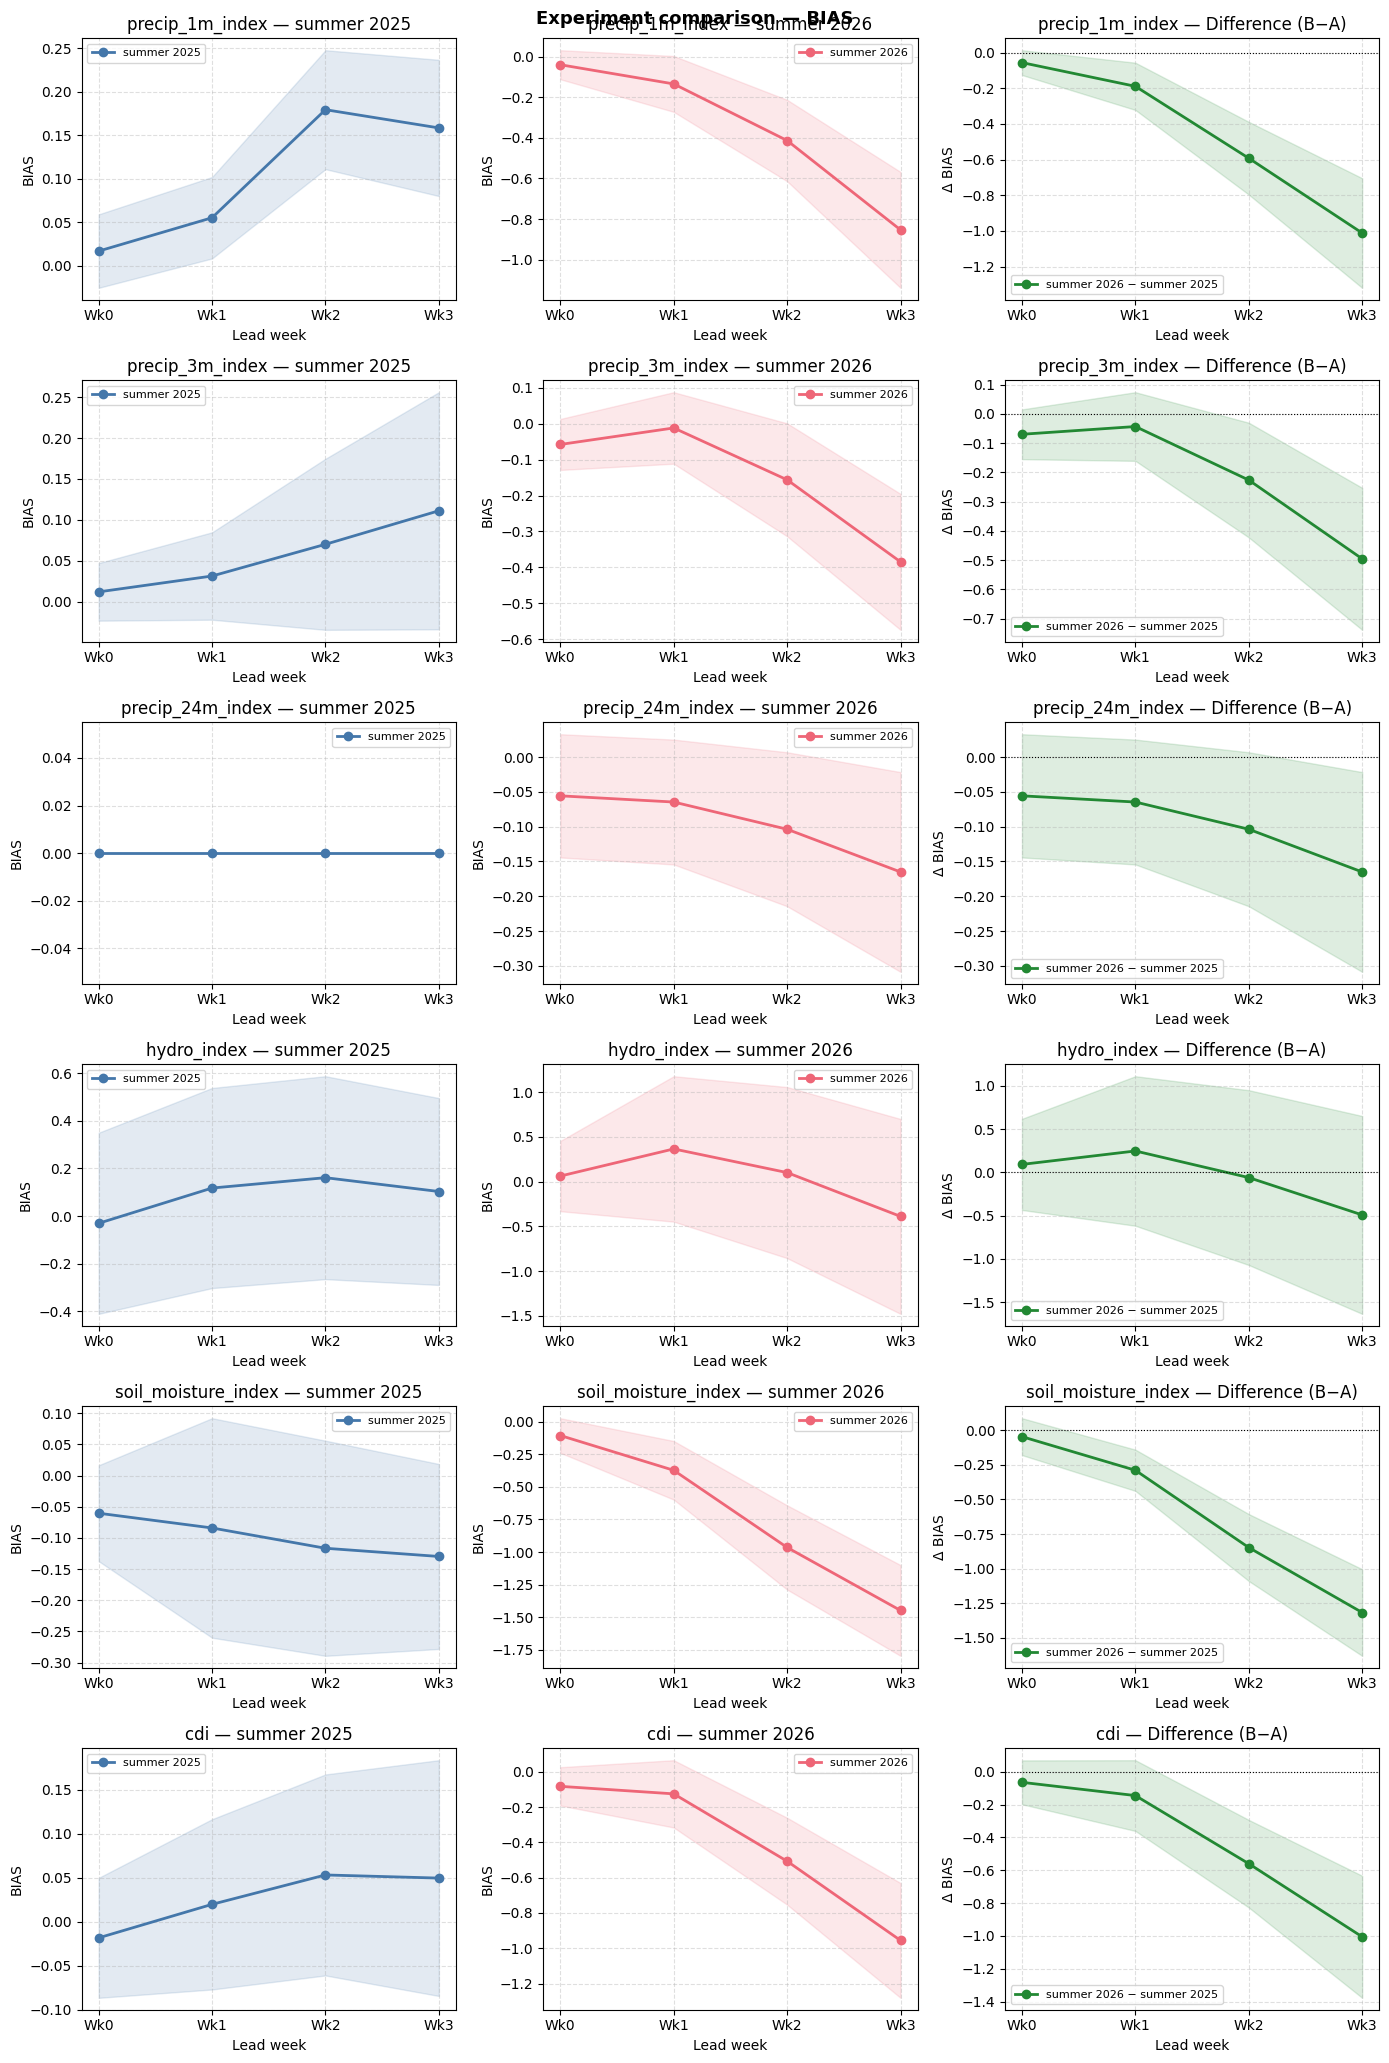

In [50]:
# Experiment comparison: period A vs period B
from drought_forecast_eval.visualization import plot_experiment_diff

# Example: compare first half vs second half of the year
DATE_RANGE_A = ("2025-07-01", "2025-10-29")
DATE_RANGE_B = ("2026-03-01", "2026-07-30")

ds_merged_a = ds_merged.sel(forecast_reference_time=slice(*DATE_RANGE_A))
ds_merged_b = ds_merged.sel(forecast_reference_time=slice(*DATE_RANGE_B))

cdi_vars = ["precip_1m_index", "precip_3m_index", "precip_24m_index", "hydro_index", "soil_moisture_index", "cdi"]
scores = ["mae","correlation", "bias"]

ds_scores_a = compute_scores(ds_merged_a, variables=cdi_vars, scores=scores, ds_ref=ds_ref_clim)
ds_scores_b = compute_scores(ds_merged_b, variables=cdi_vars, scores=scores, ds_ref=ds_ref_clim)

fig4 = plot_experiment_diff(
    ds_scores_a, ds_scores_b,
    variables=cdi_vars,
    score="bias",
    label_a="summer 2025",
    label_b="summer 2026",
)
plt.show()

In [ ]:
fig4 = plot_experiment_diff(
    ds_scores_a, ds_scores_b,
    variables=["spi_1m", "cdi"],
    score="mae",
    label_a="H2 2025",
    label_b="H1 2026",
)
plt.show()

## 7. Export results

In [ ]:
from drought_forecast_eval import ReportBuilder

builder = ReportBuilder(
    archive_dir=ARCHIVE_DIR,
    historic_path=HISTORIC_ZIP,
    date_range=DATE_RANGE,
    regions=REGIONS,
    variables=VARIABLES,
    scores="default",
    reference="climatology",
    cdi_threshold=CDI_THRESHOLD,
    shapefile_path=SHAPEFILE,
    output_dir=OUTPUT_DIR,
)

# Run the full pipeline and write all outputs
outputs = builder.run()
print("Outputs:")
for key, path in outputs.items():
    print(f"  {key}: {path}")

In [ ]:
# Or export individually:
# builder.export_netcdf(OUTPUT_DIR / "scores.nc")
# builder.export_csv(OUTPUT_DIR / "scores_summary.csv")
# builder.export_html(OUTPUT_DIR / "report.html")